# 📂 Financial Data Analytics: Forecasting, Variance Analysis, and Customer Insights  

# 📚 1.0 Introduction


<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
This section deals with the purpose, and problem statement, and contribution of this project to the sphere of knowledge. The project overview is also discussed in this section.

</div>

## 1.1 Project Overview 
____
This project leverages a **comprehensive financial dataset** containing **transaction records, customer details, and card information** spanning the **2010s decade**. The dataset is sourced from **Kaggle** and contains **1 million records** with **21 columns**. The dataset is used to perform **financial forecasting, variance analysis, and customer insights extraction**. 

🔗 **Reference Dataset:** [Financial Transactions Dataset: Analytics (Kaggle)](https://www.kaggle.com)  

The goal is to **demonstrate expertise in SQL, Python, Machine Learning, and Power BI** by performing:  
- **Financial forecasting** for revenue and expense prediction.  
- **Variance analysis** to compare budgeted vs. actual financials.  
- **Customer insights extraction** for spending behavior segmentation.  
- **Business intelligence reporting** using interactive dashboards.  


## 1.2 Key Objectives 
___


By leveraging SQL for data extraction and transformation, Python for machine learning, and Power BI for visualization, the project aims to provide actionable financial insights.

- **Financial Forecasting:** The goal is to build predictive models to forecast future revenue and expenses using historical transaction data. This involves extracting and cleaning financial data with SQL, training time-series models (ARIMA, XGBoost, LSTMs), and evaluating model performance using metrics such as RMSE, MAPE, and R² scores.

- **Variance Analysis:** The project will compare budgeted vs. actual financial performance to identify key variance drivers. Using SQL, variance percentages will be calculated across customers, merchants, and spending categories. This analysis will help detect high-variance spending patterns and uncover seasonal trends impacting financial deviations.

- **Customer Spending & Segmentation:** To understand customer behavior, clustering algorithms (K-Means, DBSCAN) will be used to categorize customers based on spending patterns. The analysis will differentiate between high-value and low-value customers by evaluating transaction trends and creating customer profiles based on spending frequency, transaction volume, and merchant categories.

- **Business Intelligence & Reporting:** The final objective is to develop a Power BI dashboard for real-time financial tracking and variance monitoring. SQL-based financial data will be integrated into Power BI to design interactive visualizations for revenue, expense, and variance trends. The dashboard will provide financial decision-makers with insights into spending behavior, revenue trends, and key financial variances.

By addressing these objectives, the project will demonstrate a strong foundation in SQL, Python, Machine Learning, and Power BI, ensuring a data-driven approach to financial analysis and forecasting.


### Importing Libraries


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('ggplot')

In [7]:
import os
from io import BytesIO
from office365.sharepoint.client_context import ClientContext
from office365.runtime.auth.user_credential import UserCredential
from dotenv import load_dotenv

load_dotenv()

True

In [8]:
# ── Step 3: Connect to SharePoint (Device Code / MFA-safe) ─────────────────
import msal, sys

SHAREPOINT_URL = os.getenv("SHAREPOINT_URL", "https://teslimuthmanadeyanju-my.sharepoint.com")
TENANT_ID      = os.getenv("SHAREPOINT_TENANT_ID", "bb484186-2595-4a79-b614-835deace0238")
CLIENT_ID      = os.getenv("SHAREPOINT_CLIENT_ID")   # from Azure App Registration
USERNAME       = os.getenv("SHAREPOINT_USER")

if not CLIENT_ID:
    raise ValueError(
        "Add SHAREPOINT_CLIENT_ID to your .env file.\n"
        "Register an app in Azure Portal > App Registrations, "
        "enable public client flows, add SharePoint delegated permissions."
    )

TOKEN_CACHE_PATH = ".msal_token_cache.json"
SCOPES           = [f"{SHAREPOINT_URL}/.default"]

# ── Persistent token cache ──────────────────────────────────────────────────
_cache = msal.SerializableTokenCache()
if os.path.exists(TOKEN_CACHE_PATH):
    _cache.deserialize(open(TOKEN_CACHE_PATH).read())

_msal_app = msal.PublicClientApplication(
    client_id=CLIENT_ID,
    authority=f"https://login.microsoftonline.com/{TENANT_ID}",
    token_cache=_cache,
)

# ── Acquire token eagerly so the prompt appears immediately ────────────────
accounts = _msal_app.get_accounts(username=USERNAME)
_token_result = None

if accounts:
    _token_result = _msal_app.acquire_token_silent(SCOPES, account=accounts[0])

if not _token_result or "access_token" not in _token_result:
    _flow = _msal_app.initiate_device_flow(scopes=SCOPES)
    if "user_code" not in _flow:
        raise ValueError(f"Device flow failed: {_flow.get('error_description')}")
    print(_flow["message"])
    sys.stdout.flush()
    _token_result = _msal_app.acquire_token_by_device_flow(_flow)

if "access_token" not in _token_result:
    raise ValueError(
        f"Auth failed: {_token_result.get('error_description', _token_result.get('error'))}"
    )

if _cache.has_state_changed:
    open(TOKEN_CACHE_PATH, "w").write(_cache.serialize())

print("Token acquired")


def _acquire_token():
    """Return the already-acquired token as a TokenResponse."""
    from office365.runtime.auth.token_response import TokenResponse
    return TokenResponse(access_token=_token_result["access_token"], token_type="Bearer")


ctx = ClientContext(SHAREPOINT_URL).with_access_token(_acquire_token)
print("Connected to SharePoint")

# ── Step 4: Loader & Saver Functions ───────────────────────────────────────
BASE_PATH = (
    "/personal/info_adeyanjuteslim_co_uk"
    "/Documents/WorkSpaceDataSources"
)
FOLDER = "FinancialTransactionsDatasetAnalytics(Kaggle)"


def list_source_files() -> pd.DataFrame:
    """List all files in the SharePoint dataset folder."""
    folder_url = f"{BASE_PATH}/{FOLDER}"
    folder = ctx.web.get_folder_by_server_relative_url(folder_url)
    files  = folder.files
    ctx.load(folder)
    ctx.load(files)
    ctx.execute_query()
    print(f"Folder resolved: {folder.serverRelativeUrl}")
    rows = [
        {
            "name": f.properties.get("Name"),
            "server_relative_url": f.properties.get("ServerRelativeUrl"),
        }
        for f in files
    ]
    if not rows:
        print("No files found — check BASE_PATH / FOLDER values above.")
        return pd.DataFrame(columns=["name", "server_relative_url"])
    out = pd.DataFrame(rows).sort_values("name").reset_index(drop=True)
    print(f"Files found: {len(out)}")
    return out


def load_from_sharepoint(filename: str, **kwargs) -> pd.DataFrame:
    """
    Load a CSV or JSON file from the SharePoint dataset folder into pandas.
    No file is saved locally.

    Args:
        filename : The file name e.g. 'transactions.csv'

    Returns:
        pd.DataFrame
    """
    ext = filename.rsplit(".", 1)[-1].lower()
    if ext not in {"csv", "json"}:
        raise ValueError("Only CSV and JSON are supported.")
    kwargs.pop("file_type", None)
    file_path = f"{BASE_PATH}/{FOLDER}/{filename}"
    buffer = BytesIO()
    ctx.web.get_file_by_server_relative_url(file_path).download(buffer).execute_query()
    buffer.seek(0)
    return pd.read_json(buffer, **kwargs) if ext == "json" else pd.read_csv(buffer, **kwargs)


def save_to_sharepoint(df: pd.DataFrame, filename: str) -> None:
    """
    Save a DataFrame as a CSV back to the SharePoint dataset folder.

    Args:
        df       : DataFrame to save
        filename : Target filename e.g. 'results.csv'
    """
    buffer = BytesIO()
    df.to_csv(buffer, index=False)
    file_bytes = buffer.getvalue()
    folder_url = f"{BASE_PATH}/{FOLDER}"
    ctx.web.get_folder_by_server_relative_url(folder_url).upload_file(
        filename, file_bytes
    ).execute_query()
    print(f"Saved {filename} to SharePoint")


# ── Step 5: List available files in the folder ─────────────────────────────
available_files = list_source_files()
available_files

Token acquired
Connected to SharePoint


ClientRequestException: ('-2147024891, System.UnauthorizedAccessException', 'Access denied.', "403 Client Error: Forbidden for url: https://teslimuthmanadeyanju-my.sharepoint.com/_api/Web/getFolderByServerRelativeUrl('%2Fpersonal%2Finfo_adeyanjuteslim_co_uk%2FDocuments%2FWorkSpaceDataSources%2FFinancialTransactionsDatasetAnalytics(Kaggle)')")

# 📚 2.0 Data Integration and SQL Setup

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
This section focuses on loading the financial transactions dataset into a SQL database, establishing relationships between tables, and ensuring data integrity. The SQL setup is crucial for subsequent data analysis, forecasting, and visualization tasks.

</div>


## 2.1 Dataset Schema & Relationships 
___

The dataset consists of multiple interconnected files, requiring structured relationships to ensure seamless data integration. The table below outlines the **primary keys, foreign keys, and purpose** of each dataset component.  

| **Dataset**                | **Primary Key**     | **Foreign Key(s) & Relationships**           | **Purpose** |
|----------------------------|--------------------|----------------------------------------------|-------------|
| `transactions_data.csv`     | `transaction_id`   | `user_id`, `card_id`, `mcc_code`            | Tracks revenue, expenses, and spending details. |
| `cards_data.csv`           | `card_id`          | `user_id`                                   | Links transactions to customers via cards. |
| `users_data.csv`           | `user_id`          | None                                        | Provides user demographics and account details. |
| `mcc_codes.json`           | `mcc_code`         | None                                        | Maps merchant category codes to business types. |
| `train_fraud_labels.json`  | `transaction_id`   | None                                        | Labels transactions as fraudulent (1) or legitimate (0). |




## 2.2 Dataset Overview
___

1. **Users Table:**   
Contains key demographic and financial information such as current_age, retirement_age, income details, total_debt, and credit_score. These fields are crucial for profiling customers and can serve as features for predicting spending patterns, risk, and future financial behavior.

2. **Cards Table:**   
Links directly to the users table through user_id and provides additional insights into customer behavior by including details like card_brand, card_type, credit_limit, and security-related attributes (e.g., has_chip, card_on_dark_web). These features can be used to segment customers or detect anomalies in card usage.

3. **MCC Codes Table:**   
Offers a mapping of merchant category codes to their descriptions, which helps classify transactions. By integrating this table with transactions, you can derive categorical features that highlight spending trends across different merchant types.

4. **Transactions Table:**   
Serves as the central repository for tracking financial activity, linking users and cards. It records transaction dates, amounts, merchant details, and even error logs. With these, you can compute aggregated metrics (like total spending per customer or monthly revenue trends) and conduct variance analysis (budgeted vs. actual amounts).

5. **Fraud Labels Table:**  
Provides a target variable for supervised learning tasks, specifically fraud detection. By associating each transaction with a fraud label, you can build models to predict fraudulent behavior based on the integrated features from the other tables.

The first step is to load the dataset into a SQL database and establish relationships between the tables to facilitate data retrieval and analysis.

## 2.3 Dataset Loading 
___


#### 2.3.1. Loading dataset: users_data

In [4]:
# 2) Pick one file from available_files["name"]
selected_file = "users_data.csv"  # change this to any filename from the list
selected_file

'users_data.csv'

In [11]:
# 3) Load the selected file into Jupyter
selected_df = load_from_sharepoint(selected_file)
selected_df.head()

Cannot get binary security token for from https://login.microsoftonline.com/extSTS.srf


ValueError: Cannot get binary security token for from https://login.microsoftonline.com/extSTS.srf

In [5]:
# Check the data types of the columns
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 2000 non-null   int64  
 1   current_age        2000 non-null   int64  
 2   retirement_age     2000 non-null   int64  
 3   birth_year         2000 non-null   int64  
 4   birth_month        2000 non-null   int64  
 5   gender             2000 non-null   object 
 6   address            2000 non-null   object 
 7   latitude           2000 non-null   float64
 8   longitude          2000 non-null   float64
 9   per_capita_income  2000 non-null   object 
 10  yearly_income      2000 non-null   object 
 11  total_debt         2000 non-null   object 
 12  credit_score       2000 non-null   int64  
 13  num_credit_cards   2000 non-null   int64  
dtypes: float64(2), int64(7), object(5)
memory usage: 218.9+ KB


It is crucial to convert the columns to their appropriate data types based on the nature of the data. This step ensures accurate analysis and processing of the information

In [6]:
def clean_users_data(data):
    data['per_capita_income'] = data['per_capita_income'].str.replace("$", "").str.replace(",", "").astype(float)
    data['yearly_income'] = data['yearly_income'].str.replace("$", "").str.replace(",", "").astype(float)
    data['total_debt'] = data['total_debt'].str.replace("$", "").str.replace(",", "").astype(float)
    
    return data

# Clean users data
users_data = clean_users_data(users)


In [7]:
# check the data types after cleaning
users_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 2000 non-null   int64  
 1   current_age        2000 non-null   int64  
 2   retirement_age     2000 non-null   int64  
 3   birth_year         2000 non-null   int64  
 4   birth_month        2000 non-null   int64  
 5   gender             2000 non-null   object 
 6   address            2000 non-null   object 
 7   latitude           2000 non-null   float64
 8   longitude          2000 non-null   float64
 9   per_capita_income  2000 non-null   float64
 10  yearly_income      2000 non-null   float64
 11  total_debt         2000 non-null   float64
 12  credit_score       2000 non-null   int64  
 13  num_credit_cards   2000 non-null   int64  
dtypes: float64(5), int64(7), object(2)
memory usage: 218.9+ KB


____

#### 2.3.2. Loading dataset: card_data

In [9]:
# SharePoint filename — loaded via load_from_sharepoint()
file_2 = "cards_data.csv"

In [10]:
# Load card data from SharePoint
cards = load_from_sharepoint(file_2)
cards.head()

,id,client_id,card_brand,card_type,card_number,expires,cvv,has_chip,num_cards_issued,credit_limit,acct_open_date,year_pin_last_changed,card_on_dark_web
0,4524,825,Visa,Debit,4344676511950444,12/2022,623,YES,2,$24295,09/2002,2008,No
1,2731,825,Visa,Debit,4956965974959986,12/2020,393,YES,2,$21968,04/2014,2014,No
2,3701,825,Visa,Debit,4582313478255491,02/2024,719,YES,2,$46414,07/2003,2004,No
3,42,825,Visa,Credit,4879494103069057,08/2024,693,NO,1,$12400,01/2003,2012,No
4,4659,825,Mastercard,Debit (Prepaid),5722874738736011,03/2009,75,YES,1,$28,09/2008,2009,No


In [11]:
# check the data types
cards.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6146 entries, 0 to 6145
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   id                     6146 non-null   int64 
 1   client_id              6146 non-null   int64 
 2   card_brand             6146 non-null   object
 3   card_type              6146 non-null   object
 4   card_number            6146 non-null   int64 
 5   expires                6146 non-null   object
 6   cvv                    6146 non-null   int64 
 7   has_chip               6146 non-null   object
 8   num_cards_issued       6146 non-null   int64 
 9   credit_limit           6146 non-null   object
 10  acct_open_date         6146 non-null   object
 11  year_pin_last_changed  6146 non-null   int64 
 12  card_on_dark_web       6146 non-null   object
dtypes: int64(6), object(7)
memory usage: 624.3+ KB


Converting columns to appropriate data types for accurate analysis and processing

In [12]:
import pandas as pd

def clean_cards_data(data):

    # Convert 'expires' to datetime
    data['expires'] = pd.to_datetime(data['expires'], format='%m/%Y', errors='coerce')

    data['credit_limit'] = (data['credit_limit'].str.replace(r'[$,]', '', regex=True).astype(float))
    
    # Convert 'acct_open_date' to datetime
    data['acct_open_date'] = pd.to_datetime(data['acct_open_date'], format='%m/%d/%Y', errors='coerce')
    
    # Convert 'year_pin_last_changed' to integer (since it contains only years)
    data['year_pin_last_changed'] = pd.to_numeric(data['year_pin_last_changed'], errors='coerce').astype('Int64')  
    
    # Handle missing values (optional, depending on your use case)
    data['expires'] = data['expires'].fillna(pd.NaT)  # Fill missing datetime with NaT
    data['credit_limit'] = data['credit_limit'].fillna(0.0)  # Fill missing credit limits with 0.0
    data['acct_open_date'] = data['acct_open_date'].fillna(pd.NaT)  # Fill missing datetime with NaT
    data['year_pin_last_changed'] = data['year_pin_last_changed'].fillna(0)  # Fill missing years with 0
    
    return data

# Clean cards data
cards_data = clean_cards_data(cards)

In [ ]:
cards_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6146 entries, 0 to 6145
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     6146 non-null   int64         
 1   client_id              6146 non-null   int64         
 2   card_brand             6146 non-null   object        
 3   card_type              6146 non-null   object        
 4   card_number            6146 non-null   int64         
 5   expires                6146 non-null   datetime64[ns]
 6   cvv                    6146 non-null   int64         
 7   has_chip               6146 non-null   object        
 8   num_cards_issued       6146 non-null   int64         
 9   credit_limit           6146 non-null   float64       
 10  acct_open_date         0 non-null      datetime64[ns]
 11  year_pin_last_changed  6146 non-null   Int64         
 12  card_on_dark_web       6146 non-null   object        
dtypes: 

____

#### 2.3.3. Loading dataset: mcc_codes_data

In [16]:
# SharePoint filename — loaded via load_from_sharepoint()
file_3 = "mcc_codes.json"

In [17]:
# Load mcc codes data from SharePoint
mcc_codes_data = load_from_sharepoint(file_3, file_type='json', orient='index')
mcc_codes_data.head()

,0
5812,Eating Places and Restaurants
5541,Service Stations
7996,"Amusement Parks, Carnivals, Circuses"
5411,"Grocery Stores, Supermarkets"
4784,Tolls and Bridge Fees


In [18]:
mcc_codes_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 109 entries, 5812 to 5733
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       109 non-null    object
dtypes: object(1)
memory usage: 1.7+ KB


___

#### 2.3.4. Load dataset: Transaction_data

In [ ]:
# SharePoint filename — loaded via load_from_sharepoint()
file_4 = "transactions_data.csv"

In [19]:
# load transactions data from SharePoint
transactions = load_from_sharepoint(file_4, parse_dates=['date'])
transactions.head()

NameError: name 'file_4' is not defined

In [ ]:
# check the data types
transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13305915 entries, 0 to 13305914
Data columns (total 12 columns):
 #   Column          Dtype         
---  ------          -----         
 0   id              int64         
 1   date            datetime64[ns]
 2   client_id       int64         
 3   card_id         int64         
 4   amount          object        
 5   use_chip        object        
 6   merchant_id     int64         
 7   merchant_city   object        
 8   merchant_state  object        
 9   zip             float64       
 10  mcc             int64         
 11  errors          object        
dtypes: datetime64[ns](1), float64(1), int64(5), object(5)
memory usage: 1.2+ GB


In [ ]:
# check for missing values
transactions.isnull().sum()

id                       0
date                     0
client_id                0
card_id                  0
amount                   0
use_chip                 0
merchant_id              0
merchant_city            0
merchant_state     1563700
zip                1652706
mcc                      0
errors            13094522
dtype: int64

This dataset contains transaction details such as transaction_id, transaction_date, user_id, card_id, merchant_id, mcc_code, amount, and other relevant information, and it is important that dollar amounts are stored as numeric values for financial analysis, thus, this will be converted to the appropriate data type using the function below.

In [ ]:
# Clean transactions data
def clean_transactions_data(transactions_df):
	"""
	Cleans the transactions data using vectorized operations:
	1. Removes dollar signs, commas, and parentheses from the `amount` column and converts it to float.
	2. Converts the `date` column to a datetime object.
	3. Handles missing values in `merchant_state`, `zip`, and `errors` columns.
	4. Returns a cleaned DataFrame.
	"""
	# Clean the `amount` column
	transactions_df['amount'] = (
		transactions_df['amount']
		.str.replace('$', '', regex=False)  # Remove dollar signs
		.str.replace(',', '', regex=False)  # Remove commas
		.str.replace('(', '-', regex=False)  # Replace opening parenthesis with negative sign
		.str.replace(')', '', regex=False)  # Remove closing parenthesis
		.astype(float)  # Convert to float
	)
	
	# Convert the `date` column to datetime
	transactions_df['date'] = pd.to_datetime(transactions_df['date'])
	
	# Handle missing values in `merchant_state`, `zip`, and `errors`
	transactions_df['merchant_state'] = transactions_df['merchant_state'].fillna('unknown')
	transactions_df['zip'] = transactions_df['zip'].fillna('unknown')
	transactions_df['errors'] = transactions_df['errors'].fillna('No Errors')
	
	# Convert specific columns to integers
	int_columns = ['id', 'client_id', 'card_id', 'merchant_id', 'mcc']
	transactions_df[int_columns] = transactions_df[int_columns].astype(int)
	
	# Rename columns to match the database schema (optional)
	transactions_df = transactions_df.rename(columns={
		'id': 'transaction_id',
		'client_id': 'user_id',
		'date': 'transaction_date',
		'mcc': 'mcc_code'
	})
	
	return transactions_df


In [ ]:
# Clean transactions data
transactions_data = clean_transactions_data(transactions)

In [ ]:
transactions_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13305915 entries, 0 to 13305914
Data columns (total 12 columns):
 #   Column            Dtype         
---  ------            -----         
 0   transaction_id    int64         
 1   transaction_date  datetime64[ns]
 2   user_id           int64         
 3   card_id           int64         
 4   amount            float64       
 5   use_chip          object        
 6   merchant_id       int64         
 7   merchant_city     object        
 8   merchant_state    object        
 9   zip               object        
 10  mcc_code          int64         
 11  errors            object        
dtypes: datetime64[ns](1), float64(1), int64(5), object(5)
memory usage: 1.2+ GB


____

#### 2.3.5. Loading dataset: Train_fraud_data

In [ ]:
# Load fraud labels data from SharePoint
fraud_labels_data = load_from_sharepoint("train_fraud_labels.json", file_type="json")
fraud_labels_data.head()

,target
10000000,No
10000002,No
10000003,No
10000004,No
10000005,No


In [ ]:
fraud_labels_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8914963 entries, 10000000 to 9999998
Data columns (total 1 columns):
 #   Column  Dtype 
---  ------  ----- 
 0   target  object
dtypes: object(1)
memory usage: 136.0+ MB


## 2.4 SQL Database Initialization
___

The next step is the Database Initialization, which involves creating a new database, establishing connections, and loading the dataset into the database. This process is crucial for subsequent data analysis, forecasting, and visualization tasks.

In [ ]:
import duckdb

print("DuckDB SQL engine loaded ✓  (no credentials needed)")
print("Queries run directly against pandas DataFrames — no server, no config")

MySQL credentials loaded successfully.


## 2.5 Connect to SQL Database
___

After initializing the database, the next step is to connect to the SQL database using Python. This connection is essential for querying the database, extracting data, and performing various data analysis tasks.

In [ ]:
# In-memory DuckDB connection — queries DataFrames directly, no server required
conn = duckdb.connect(":memory:")

conn.register("users",        users_data)
conn.register("cards",        cards_data)
conn.register("mcc_codes",    mcc_codes_data)
conn.register("transactions", transactions_data)
conn.register("fraud_labels", fraud_labels_data)

print("Tables registered with DuckDB ✓")
print("Available: users, cards, mcc_codes, transactions, fraud_labels")

Database 'financial_transactions_db' created successfully and connected.


## 2.6 Create Tables
___

Followinng the set up of the  database, the next step is create the tables in the database, and insert data. The tables will be created based on the schema and relationships defined earlier.

The tables will be created:
- users
- cards
- mcc_codes
- transactions
- fraud_labels

In [ ]:
# Table schema managed by DuckDB — no DDL needed (DataFrames registered above)

In [ ]:
# Table schema managed by DuckDB — no DDL needed (DataFrames registered above)

In [ ]:
# Table schema managed by DuckDB — no DDL needed (DataFrames registered above)

In [ ]:
# Table schema managed by DuckDB — no DDL needed (DataFrames registered above)

In [ ]:
# Table schema managed by DuckDB — no DDL needed (DataFrames registered above)

In [ ]:
# DuckDB tables are registered — ready to query

Table 'users' created successfully.
Table 'cards' created successfully.
Table 'mcc_codes' created successfully.
Table 'transactions' created successfully.
Table 'fraud_labels' created successfully.


After creating the tables, the next step is to establish relationships between them to ensure data integrity and consistency. After that, we will proceed to the next section of inspecting the data into the tables.

## 2.7 Insert data into the tables
___

#### 2.7.1 Insert Data into: User Table
___

In [ ]:
users_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 2000 non-null   int64  
 1   current_age        2000 non-null   int64  
 2   retirement_age     2000 non-null   int64  
 3   birth_year         2000 non-null   int64  
 4   birth_month        2000 non-null   int64  
 5   gender             2000 non-null   object 
 6   address            2000 non-null   object 
 7   latitude           2000 non-null   float64
 8   longitude          2000 non-null   float64
 9   per_capita_income  2000 non-null   float64
 10  yearly_income      2000 non-null   float64
 11  total_debt         2000 non-null   float64
 12  credit_score       2000 non-null   int64  
 13  num_credit_cards   2000 non-null   int64  
dtypes: float64(5), int64(7), object(2)
memory usage: 218.9+ KB


In [ ]:
# Data loaded from SharePoint into DataFrames — no insertion needed
# DuckDB queries the DataFrames in-memory

✅ Users data inserted successfully.


####  2.7.2 Insert Data into: Cards Table
___

In [ ]:
cards_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6146 entries, 0 to 6145
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     6146 non-null   int64         
 1   client_id              6146 non-null   int64         
 2   card_brand             6146 non-null   object        
 3   card_type              6146 non-null   object        
 4   card_number            6146 non-null   int64         
 5   expires                6146 non-null   datetime64[ns]
 6   cvv                    6146 non-null   int64         
 7   has_chip               6146 non-null   object        
 8   num_cards_issued       6146 non-null   int64         
 9   credit_limit           6146 non-null   float64       
 10  acct_open_date         0 non-null      datetime64[ns]
 11  year_pin_last_changed  6146 non-null   Int64         
 12  card_on_dark_web       6146 non-null   object        
dtypes: 

In [ ]:
# Data loaded from SharePoint into DataFrames — no insertion needed
# DuckDB queries the DataFrames in-memory

✅ Cards data inserted successfully.


#### 2.7.3 Insert Data into: MCC Codes Table
___

In [ ]:
mcc_codes_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 109 entries, 5812 to 5733
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       109 non-null    object
dtypes: object(1)
memory usage: 1.7+ KB


In [ ]:
# Data loaded from SharePoint into DataFrames — no insertion needed
# DuckDB queries the DataFrames in-memory

✅ MCC Codes data inserted successfully.


#### 2.7.4 Insert Data into: Transactions Table
____

In [ ]:
transactions_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13305915 entries, 0 to 13305914
Data columns (total 12 columns):
 #   Column            Dtype         
---  ------            -----         
 0   transaction_id    int64         
 1   transaction_date  datetime64[ns]
 2   user_id           int64         
 3   card_id           int64         
 4   amount            float64       
 5   use_chip          object        
 6   merchant_id       int64         
 7   merchant_city     object        
 8   merchant_state    object        
 9   zip               object        
 10  mcc_code          int64         
 11  errors            object        
dtypes: datetime64[ns](1), float64(1), int64(5), object(5)
memory usage: 1.2+ GB


In [ ]:
# Data loaded from SharePoint into DataFrames — no insertion needed
# DuckDB queries the DataFrames in-memory

✅ Transactions data inserted successfully.


#### 2.7.5 Insert Data into:  Train_fraud_data Table
_____


In [ ]:
fraud_labels_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8914963 entries, 10649266 to 15151926
Data columns (total 1 columns):
 #   Column  Dtype 
---  ------  ----- 
 0   target  object
dtypes: object(1)
memory usage: 136.0+ MB


In [ ]:
# Data loaded from SharePoint into DataFrames — no insertion needed
# DuckDB queries the DataFrames in-memory

✅ Fraud Labels data inserted successfully.


# 📚 3.0 SQL Data Extraction
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
In this section, we focus on feature engineering—the process of creating new, informative variables from the existing raw data. These engineered features are not directly available in the original dataset but are derived by combining and transforming columns through SQL queries. The goal is to enhance the predictive power of machine learning models and improve the accuracy of financial forecasts.
</div>

DuckDB queries the DataFrames directly — all tables registered above. No reconnection needed.

In [ ]:
def run_query(query: str) -> pd.DataFrame:
    """Execute a SQL query against the registered DataFrames using DuckDB."""
    return conn.execute(query).df()

print("run_query() ready — powered by DuckDB ✓")

The objective of this project is 4-fold:
1. **Financial Forecasting:** Predict future revenue and expenses using historical transaction data.
2. **Variance Analysis:** Compare budgeted vs. actual financial performance to identify key variance drivers.
3. **Customer Insights:** Understand customer behavior through spending segmentation and clustering.
4. **Business Intelligence:** Develop Power BI dashboards for real-time financial tracking and variance monitoring.

Thus, feature engineering will focus on creating variables that capture each of those objectives. The features will be derived from the transactions, users, and cards tables to provide a comprehensive view of financial activity, customer behavior, and spending patterns. Each section provides: 
- Feature List: A detailed breakdown of the features created.
- SQL Queries: To extract and transform data for use in machine learning models or BI tools.



#### 3.1. Financial Forecasting Features Extracted
___


The purpose of financial forecasting is to predict future revenue and expenses based on historical transaction data. To achieve this, we need to create features that capture trends, seasonality, and other patterns in the financial data. The following features will be engineered for financial forecasting:



| Feature                | Description                                          | SQL Extraction                                                                 |
|------------------------|------------------------------------------------------|-------------------------------------------------------------------------------|
| **month_start**        | Start of the month for each transaction period       | `DATE_FORMAT(transaction_date, '%Y-%m-01')`                                   |
| **transaction_year**   | Year of transaction                                  | `YEAR(transaction_date)`                                                      |
| **transaction_month**  | Month of transaction                                 | `MONTH(transaction_date)`                                                     |
| **transaction_quarter**| Quarter of transaction                               | `QUARTER(transaction_date)`                                                   |
| **total_revenue**      | Total revenue for the given month                    | `SUM(amount)`                                                                 |
| **lag_1_month**        | Revenue from the previous month                      | `LAG(total_revenue, 1) OVER (ORDER BY month_start)`                           |
| **lag_2_month**        | Revenue from two months prior                        | `LAG(total_revenue, 2) OVER (ORDER BY month_start)`                           |
| **lag_3_month**        | Revenue from three months prior                      | `LAG(total_revenue, 3) OVER (ORDER BY month_start)`                           |
| **rolling_avg_3_months**| 3-month moving average of revenue                   | `AVG(total_revenue) OVER (ORDER BY month_start ROWS BETWEEN 2 PRECEDING AND CURRENT ROW)` |
| **rolling_avg_6_months**| 6-month moving average of revenue                   | `AVG(total_revenue) OVER (ORDER BY month_start ROWS BETWEEN 5 PRECEDING AND CURRENT ROW)` |
| **cumulative_revenue** | Cumulative revenue from dataset start               | `SUM(total_revenue) OVER (ORDER BY month_start)`                              |
| **month_over_month_growth**| MoM revenue change (%)                             | `(total_revenue - LAG(total_revenue, 1) OVER (ORDER BY month_start)) / NULLIF(LAG(total_revenue, 1), 0) * 100` |





This SQL analysis tracks **monthly revenue performance** and enriches it with **time-based features** such as lagged revenue, rolling averages, cumulative totals, and month-over-month growth. It is designed to uncover business trends, growth signals, and seasonality for forecasting or decision-making. The sql query will be divided into three part which is as follows:
- CTE monthly_revenue 
- CTE enhance_revenue 
- Final_result 

**1. CTE: `monthly_revenue`**

This Common Table Expression (CTE) calculates **total monthly revenue** from the `transactions` table:

In [ ]:

WITH monthly_revenue AS (
    SELECT 
        strftime(transaction_date, '%Y-%m-01') AS month_start,  -- Normalize to 1st of month
        YEAR(transaction_date) AS transaction_year,
        MONTH(transaction_date) AS transaction_month,
        QUARTER(transaction_date) AS transaction_quarter,
        SUM(amount) AS total_revenue
    FROM transactions
    GROUP BY month_start, 
             transaction_year, 
             transaction_month, 
             transaction_quarter)

**2. CTE: enhanced_revenue**

This second CTE builds analytical features from the monthly revenue data.

In [ ]:
enhanced_revenue AS (
    SELECT 
        month_start,
        transaction_year,
        transaction_month,
        transaction_quarter,
        total_revenue,

        -- Lag Features
        LAG(total_revenue, 1) OVER (ORDER BY month_start) AS lag_1_month,
        LAG(total_revenue, 2) OVER (ORDER BY month_start) AS lag_2_month,
        LAG(total_revenue, 3) OVER (ORDER BY month_start) AS lag_3_month,

        -- Rolling Averages
        AVG(total_revenue) OVER (ORDER BY month_start ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) AS rolling_avg_3_months,
        AVG(total_revenue) OVER (ORDER BY month_start ROWS BETWEEN 5 PRECEDING AND CURRENT ROW) AS rolling_avg_6_months,

        -- Cumulative Revenue
        SUM(total_revenue) OVER (ORDER BY month_start) AS cumulative_revenue,

        -- Month-over-Month Growth (%)
        (total_revenue - LAG(total_revenue, 1) OVER (ORDER BY month_start)) / 
        NULLIF(LAG(total_revenue, 1) OVER (ORDER BY month_start), 0) * 100 AS month_over_month_growth
    FROM monthly_revenue
)

**3. Final Output**

The final query returns all computed metrics in chronological order:

In [ ]:
SELECT * FROM enhanced_revenue
ORDER BY month_start;

___

Combinning all the code togther to extract the information 

In [ ]:
query = """

WITH monthly_revenue AS (
    SELECT 
        strftime(transaction_date, '%Y-%m-01') AS month_start,
        YEAR(transaction_date) AS transaction_year,
        MONTH(transaction_date) AS transaction_month,
        QUARTER(transaction_date) AS transaction_quarter,
        SUM(amount) AS total_revenue
    FROM transactions
    GROUP BY month_start, transaction_year, transaction_month, transaction_quarter
),
enhanced_revenue AS (
    SELECT 
        month_start,
        transaction_year,
        transaction_month,
        transaction_quarter,
        total_revenue,
        -- Lag features: Previous months' revenues
        LAG(total_revenue, 1) OVER (ORDER BY month_start) AS lag_1_month,
        LAG(total_revenue, 2) OVER (ORDER BY month_start) AS lag_2_month,
        LAG(total_revenue, 3) OVER (ORDER BY month_start) AS lag_3_month,
        
        -- Rolling averages for trend analysis
        AVG(total_revenue) OVER (ORDER BY month_start ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) AS rolling_avg_3_months,
        AVG(total_revenue) OVER (ORDER BY month_start ROWS BETWEEN 5 PRECEDING AND CURRENT ROW) AS rolling_avg_6_months,

        -- Cumulative revenue for trend detection
        SUM(total_revenue) OVER (ORDER BY month_start) AS cumulative_revenue,

        -- Month-over-Month Revenue Growth
        (total_revenue - LAG(total_revenue, 1) OVER (ORDER BY month_start)) / NULLIF(LAG(total_revenue, 1) OVER (ORDER BY month_start), 0) * 100 AS month_over_month_growth
    FROM monthly_revenue
)
SELECT * FROM enhanced_revenue
ORDER BY month_start;



"""

# Execute the query and display the resulting DataFrame
financial_forecasting_data = run_query(query)
financial_forecasting_data.head()

,month_start,transaction_year,transaction_month,transaction_quarter,total_revenue,lag_1_month,lag_2_month,lag_3_month,rolling_avg_3_months,rolling_avg_6_months,cumulative_revenue,month_over_month_growth
0,2010-01-01,2010,1,1,4372532.12,NaN,NaN,NaN,4.372532e+06,4.372532e+06,4372532.12,NaN
1,2010-02-01,2010,2,1,4103170.24,4372532.12,NaN,NaN,4.237851e+06,4.237851e+06,8475702.36,-6.160318
2,2010-03-01,2010,3,1,4539853.38,4103170.24,4372532.12,NaN,4.338519e+06,4.338519e+06,13015555.74,10.642579
3,2010-04-01,2010,4,2,4407951.33,4539853.38,4103170.24,4372532.12,4.350325e+06,4.355877e+06,17423507.07,-2.905425
4,2010-05-01,2010,5,2,4610601.80,4407951.33,4539853.38,4103170.24,4.519469e+06,4.406822e+06,22034108.87,4.597384


In [ ]:
# Save results to SharePoint
save_to_sharepoint(financial_forecasting_data, "financial_forecasting_data.csv")

#### 3.2 . Variance Analysis Features Extracted
___



The purpise of variance analysis is to compare budgeted vs. actual financial performance to identify key variance drivers. The following features will be engineered for variance analysis:


| Feature                      | Description                                      | SQL Extraction                                                                 |
|------------------------------|--------------------------------------------------|-------------------------------------------------------------------------------|
| actual_spending              | Total actual spending per transaction            | `amount`                                                                      |
| budgeted_spending            | Estimated budgeted spending using historical averages | `AVG(amount) OVER (PARTITION BY user_id, YEAR(transaction_date), MONTH(transaction_date))` |
| variance                     | Difference between actual and budgeted spending  | `amount - budgeted_spending`                                                 |
| variance_pct                 | Percentage variance                              | `((amount - budgeted_spending) / budgeted_spending) * 100`                   |
| total_variance_by_customer   | Customer-level variance                          | `SUM(variance) OVER (PARTITION BY user_id)`                                  |
| total_variance_by_merchant   | Merchant-level variance                          | `SUM(variance) OVER (PARTITION BY mcc_code)`                                 |
| monthly_variance             | Variance grouped by time                         | `SUM(variance) OVER (PARTITION BY YEAR(transaction_date), MONTH(transaction_date))` |

In [ ]:
query = """

WITH user_budget AS (
    -- Estimate budgeted spending using historical averages per user per month
    SELECT 
        user_id,
        YEAR(transaction_date) AS transaction_year,
        MONTH(transaction_date) AS transaction_month,
        AVG(amount) AS budgeted_spending
    FROM transactions
    GROUP BY user_id, transaction_year, transaction_month
),
transaction_variance AS (
    -- Calculate actual spending, variance, and variance percentage
    SELECT 
        t.transaction_id,
        t.user_id,
        t.amount AS actual_spending,
        ub.budgeted_spending,
        (t.amount - ub.budgeted_spending) AS variance,
        CASE 
            WHEN ub.budgeted_spending <> 0 THEN ((t.amount - ub.budgeted_spending) / ub.budgeted_spending) * 100 
            ELSE NULL 
        END AS variance_pct
    FROM transactions t
    LEFT JOIN user_budget ub 
    ON t.user_id = ub.user_id 
    AND YEAR(t.transaction_date) = ub.transaction_year 
    AND MONTH(t.transaction_date) = ub.transaction_month
)
SELECT 
    tv.*,
    SUM(tv.variance) OVER (PARTITION BY tv.user_id) AS total_variance_by_customer,
    SUM(tv.variance) OVER (PARTITION BY t.mcc_code) AS total_variance_by_merchant,
    SUM(tv.variance) OVER (PARTITION BY YEAR(t.transaction_date), MONTH(t.transaction_date)) AS monthly_variance
FROM transaction_variance tv
JOIN transactions t ON tv.transaction_id = t.transaction_id
ORDER BY variance_pct DESC;


"""

# Execute the query and display the resulting DataFrame
spending_variance_analysis_data = run_query(query)
spending_variance_analysis_data.head()

NameError: name 'run_query' is not defined

In [ ]:
# Save results to SharePoint
save_to_sharepoint(spending_variance_analysis_data, "spending_variance_analysis_data.csv")

#### 3.3 . Customer Insights Features Extracted
____


The purpose of this is to identify customer spending patterns and anomalies in the transactions data. The query calculates the budgeted spending for each user based on historical averages per user per month. It then calculates the actual spending, variance, and variance percentage for each transaction. Additionally, it calculates the total variance by customer, total variance by merchant, and monthly variance. This analysis can help identify customers with significant spending variances, merchants with high variance in transactions, and months with unusual spending patterns.



| Feature                   | Description                                      | SQL Extraction                                                                 |
|---------------------------|--------------------------------------------------|-------------------------------------------------------------------------------|
| transaction_count         | Number of transactions per user                 | `COUNT(transaction_id)`                                                       |
| total_spending            | Total amount spent per user                     | `SUM(amount)`                                                                 |
| avg_transaction_value     | Average transaction amount                      | `AVG(amount)`                                                                 |
| spending_by_category      | Spending distribution across merchant categories | `SUM(amount) OVER (PARTITION BY user_id, mcc_code)`                           |
| transaction_frequency     | Number of transactions per month                | `COUNT(transaction_id) OVER (PARTITION BY user_id, YEAR(transaction_date), MONTH(transaction_date))` |

In [ ]:

query = """
WITH user_spending AS (
    SELECT 
        t.user_id,
        t.mcc_code,
        COUNT(t.transaction_id) AS transaction_count,
        SUM(t.amount) AS total_spending,
        AVG(t.amount) AS avg_transaction_value
    FROM transactions t
    GROUP BY t.user_id, t.mcc_code
),
transaction_details AS (
    SELECT 
        t.user_id,
        t.mcc_code,
        YEAR(t.transaction_date) AS transaction_year,
        MONTH(t.transaction_date) AS transaction_month,
        COUNT(t.transaction_id) AS monthly_transaction_count
    FROM transactions t
    GROUP BY t.user_id, t.mcc_code, transaction_year, transaction_month
)
SELECT 
    us.user_id,
    us.mcc_code,
    us.transaction_count,
    us.total_spending,
    us.avg_transaction_value,
    td.monthly_transaction_count AS transaction_frequency
FROM user_spending us
LEFT JOIN transaction_details td
ON us.user_id = td.user_id AND us.mcc_code = td.mcc_code;

"""

# Execute the query and display the resulting DataFrame
customer_spending_segmentation_data = run_query(query)
customer_spending_segmentation_data.head()


,user_id,mcc_code,transaction_count,total_spending,avg_transaction_value,transaction_frequency
0,1556,5499,844,14317.7,16.9641,6
1,1556,5499,844,14317.7,16.9641,3
2,1556,5499,844,14317.7,16.9641,6
3,1556,5499,844,14317.7,16.9641,6
4,1556,5499,844,14317.7,16.9641,3


In [ ]:
# Save results to SharePoint
save_to_sharepoint(customer_spending_segmentation_data, "customer_spending_segmentation_data.csv")

#### 3.4 Business Intelligence Features
___


The purpose of this is to develop Power BI dashboards for real-time financial tracking and variance monitoring. The query calculates the total revenue for each time period, the revenue from the previous month, revenue from two months ago, 3-month moving average of revenue, and cumulative revenue. These features can be used to track revenue trends, identify seasonality patterns, and forecast future revenue.



| Metric Category      | Description                                  |
|----------------------|----------------------------------------------|
| Revenue Trends       | Total revenue and growth trends             |
| Spending Patterns    | High-spending users and categories          |
| Variance Reports     | Budgeted vs. actual spending                |
| Fraud Monitoring     | Transaction anomalies                       |

In [ ]:

query = """

SELECT 
    t.transaction_id,
    t.transaction_date,
    t.user_id,
    t.amount,
    mc.category_description AS merchant_category,
    f.is_fraud
FROM transactions t
LEFT JOIN mcc_codes mc ON t.mcc_code = mc.mcc_code
LEFT JOIN fraud_labels f ON t.transaction_id = f.transaction_id;


"""

# Execute the query and display the resulting DataFrame
business_intelligence_data = run_query(query)
business_intelligence_data.head()


,transaction_id,transaction_date,user_id,amount,merchant_category,is_fraud
0,7475327,2010-01-01,1556,-77.00,Miscellaneous Food Stores,0.0
1,7475328,2010-01-01,561,14.57,Department Stores,0.0
2,7475329,2010-01-01,1129,80.00,Money Transfer,0.0
3,7475331,2010-01-01,430,200.00,Money Transfer,NaN
4,7475332,2010-01-01,848,46.41,Drinking Places (Alcoholic Beverages),0.0


In [ ]:
# Save results to SharePoint
save_to_sharepoint(business_intelligence_data, "business_intelligence_data.csv")

# 📚 4. Data Visualisation 
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
This section focuses on data visualization using Power BI, and python libraries such as Matplotlib, Seaborn, and Plotly. The goal is to create interactive dashboards and visualizations that provide insights into revenue trends, expense patterns, customer segmentation, and financial variances. The visualizations will be used to facilitate data-driven decision-making and enhance financial analysis.
</div>

### financial forecasting
___

In [ ]:
# financial_forecasting_data already in memory from run_query above
financial_forecasting_data.head()

,month_start,transaction_year,transaction_month,transaction_quarter,total_revenue,lag_1_month,lag_2_month,lag_3_month,rolling_avg_3_months,rolling_avg_6_months,cumulative_revenue,month_over_month_growth
0,2010-01-01,2010,1,1,4372532.12,NaN,NaN,NaN,4.372532e+06,4.372532e+06,4372532.12,NaN
1,2010-02-01,2010,2,1,4103170.24,4372532.12,NaN,NaN,4.237851e+06,4.237851e+06,8475702.36,-6.160318
2,2010-03-01,2010,3,1,4539853.38,4103170.24,4372532.12,NaN,4.338519e+06,4.338519e+06,13015555.74,10.642579
3,2010-04-01,2010,4,2,4407951.33,4539853.38,4103170.24,4372532.12,4.350325e+06,4.355877e+06,17423507.07,-2.905425
4,2010-05-01,2010,5,2,4610601.80,4407951.33,4539853.38,4103170.24,4.519469e+06,4.406822e+06,22034108.87,4.597384


In [ ]:
financial_forecasting_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118 entries, 0 to 117
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   month_start              118 non-null    object 
 1   transaction_year         118 non-null    int64  
 2   transaction_month        118 non-null    int64  
 3   transaction_quarter      118 non-null    int64  
 4   total_revenue            118 non-null    float64
 5   lag_1_month              117 non-null    float64
 6   lag_2_month              116 non-null    float64
 7   lag_3_month              115 non-null    float64
 8   rolling_avg_3_months     118 non-null    float64
 9   rolling_avg_6_months     118 non-null    float64
 10  cumulative_revenue       118 non-null    float64
 11  month_over_month_growth  117 non-null    float64
dtypes: float64(8), int64(3), object(1)
memory usage: 11.2+ KB


In [ ]:
numerical_cols = ['total_revenue', 
                  'lag_1_month', 
                  'lag_2_month', 'lag_3_month', 
                  'rolling_avg_3_months', 
                  'rolling_avg_6_months', 
                  'cumulative_revenue', 
                  'month_over_month_growth']

In [ ]:
financial_forecasting_data[numerical_cols].describe().round(2)

,total_revenue,lag_1_month,lag_2_month,lag_3_month,rolling_avg_3_months,rolling_avg_6_months,cumulative_revenue,month_over_month_growth
count,118.00,117.00,116.00,115.00,118.00,118.00,1.180000e+02,117.00
mean,4846063.75,4844830.93,4844785.76,4843191.89,4840844.08,4832595.99,2.835548e+08,0.23
std,210898.45,211378.10,212294.58,212525.42,178183.05,180015.24,1.669638e+08,4.81
min,4103170.24,4103170.24,4103170.24,4103170.24,4237851.18,4237851.18,4.372532e+06,-10.18
25%,4699943.51,4693705.97,4692302.04,4690898.11,4730534.86,4715485.73,1.394054e+08,-2.91
50%,4896875.22,4889663.36,4896875.22,4889663.36,4893947.22,4912720.12,2.812534e+08,0.04
75%,5015316.94,5015639.69,5015789.73,5014994.19,4983150.60,4960331.11,4.265553e+08,3.20
max,5123666.67,5123666.67,5123666.67,5123666.67,5069963.29,5037587.38,5.718355e+08,13.02


In [ ]:
corr_matrix = financial_forecasting_data[numerical_cols].corr().round(2)
corr_matrix

,total_revenue,lag_1_month,lag_2_month,lag_3_month,rolling_avg_3_months,rolling_avg_6_months,cumulative_revenue,month_over_month_growth
total_revenue,1.00,0.42,0.60,0.56,0.84,0.80,0.66,0.51
lag_1_month,0.42,1.00,0.42,0.60,0.76,0.76,0.66,-0.56
lag_2_month,0.60,0.42,1.00,0.42,0.84,0.79,0.67,0.13
lag_3_month,0.56,0.60,0.42,1.00,0.66,0.79,0.67,-0.03
rolling_avg_3_months,0.84,0.76,0.84,0.66,1.00,0.96,0.82,0.04
rolling_avg_6_months,0.80,0.76,0.79,0.79,0.96,1.00,0.86,0.01
cumulative_revenue,0.66,0.66,0.67,0.67,0.82,0.86,1.00,-0.02
month_over_month_growth,0.51,-0.56,0.13,-0.03,0.04,0.01,-0.02,1.00


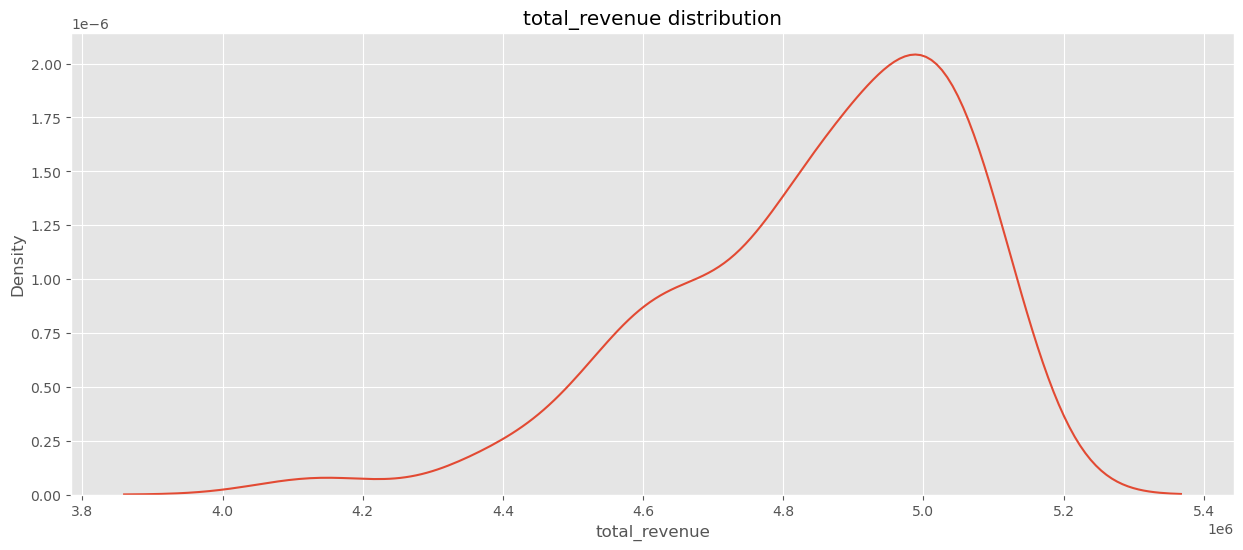

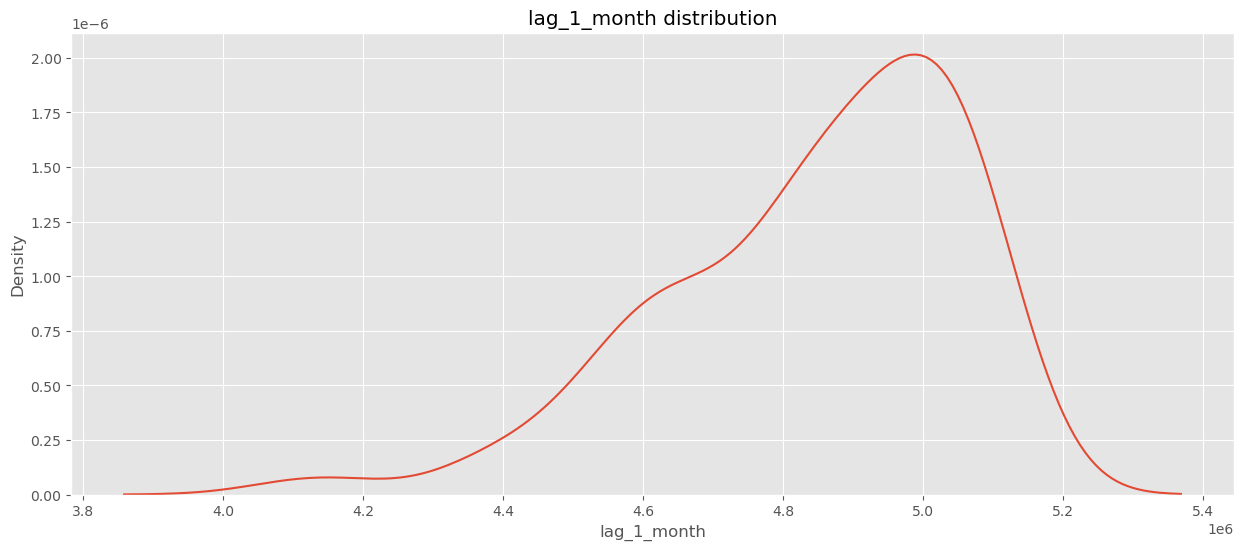

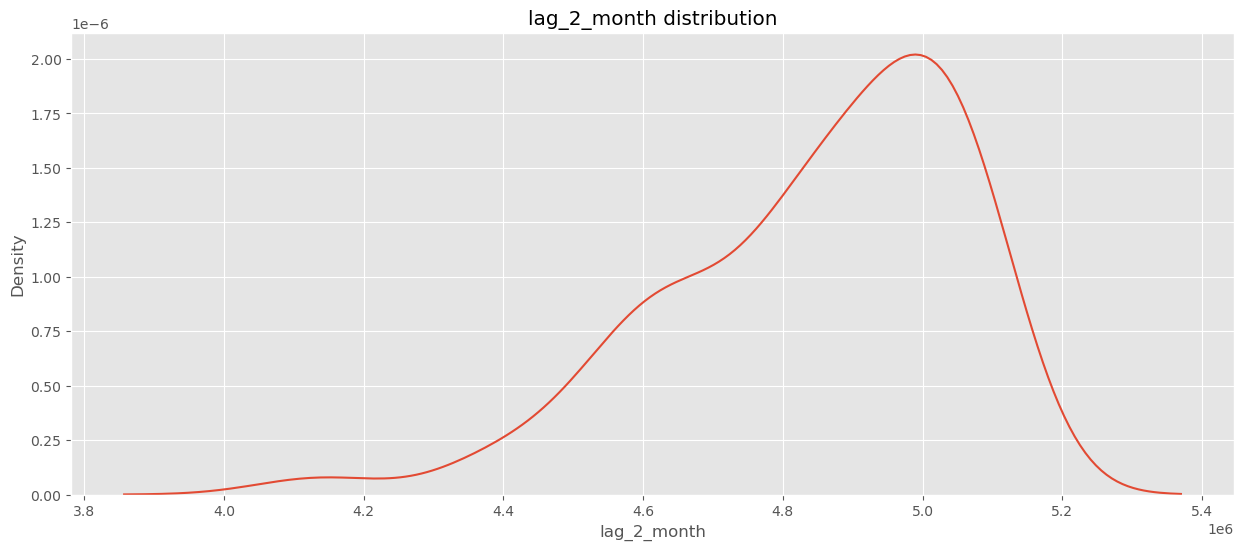

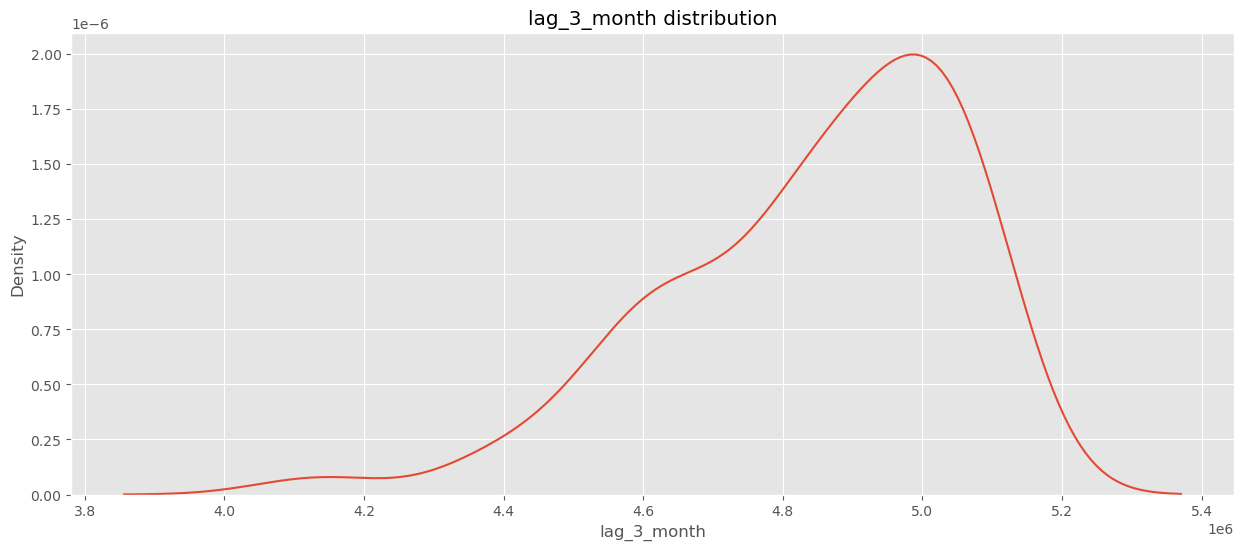

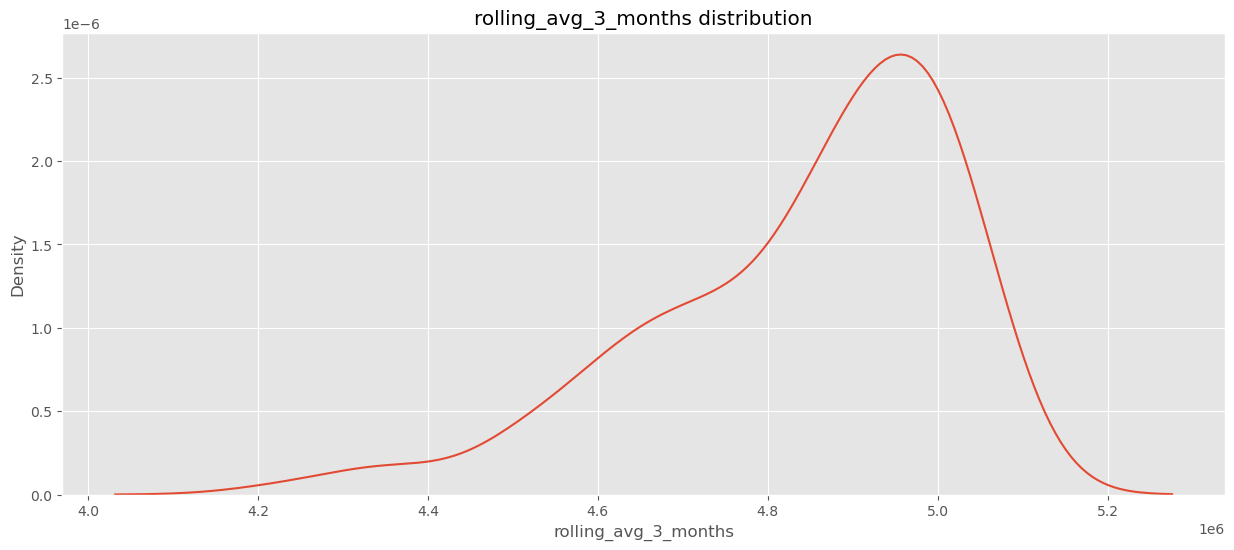

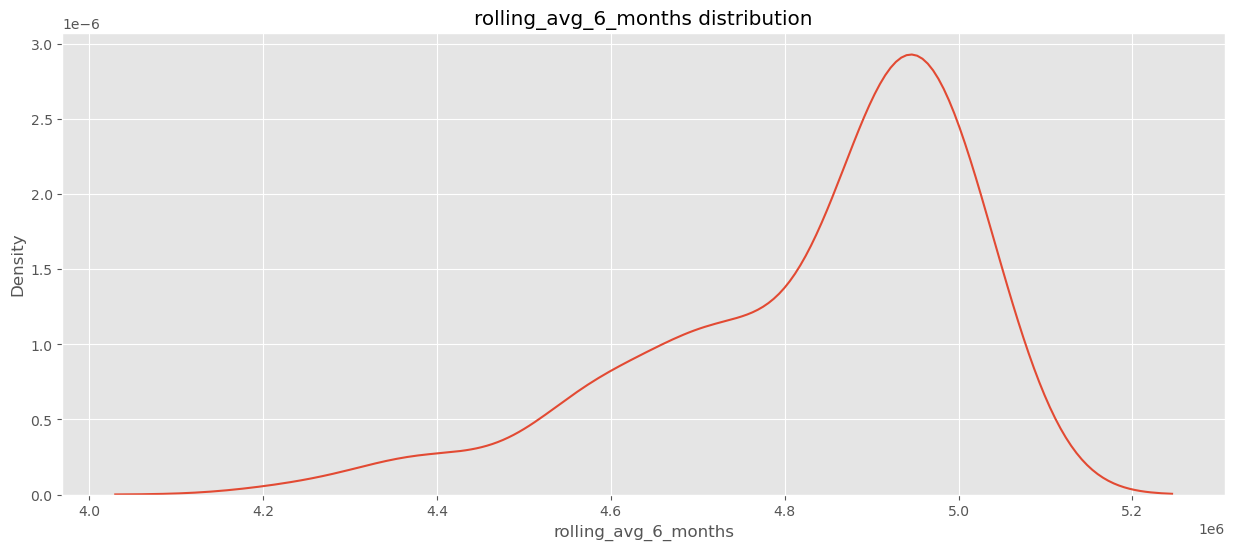

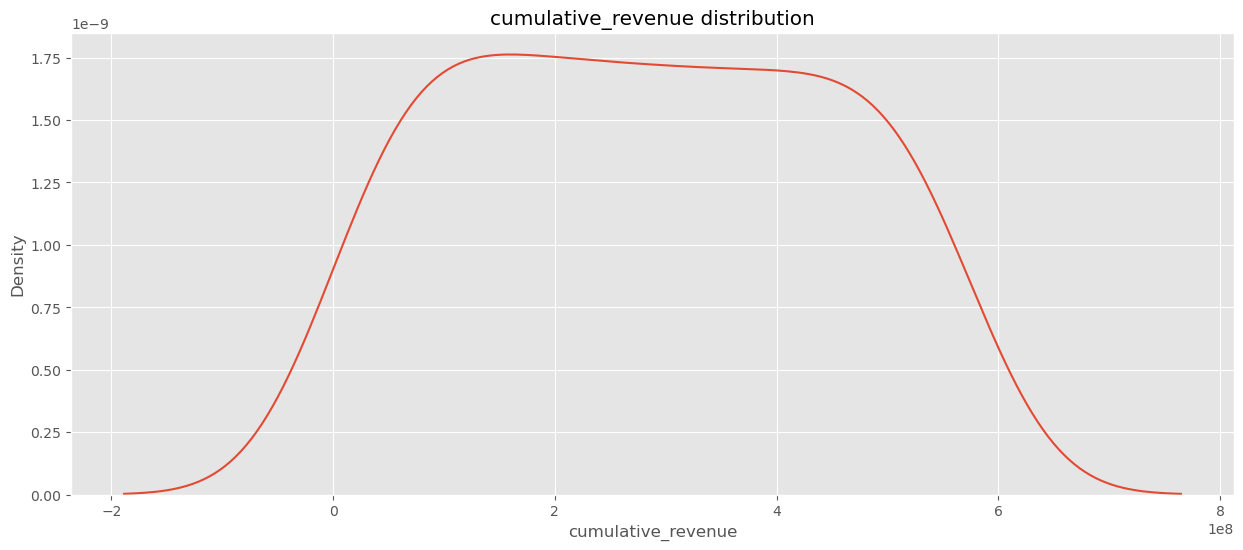

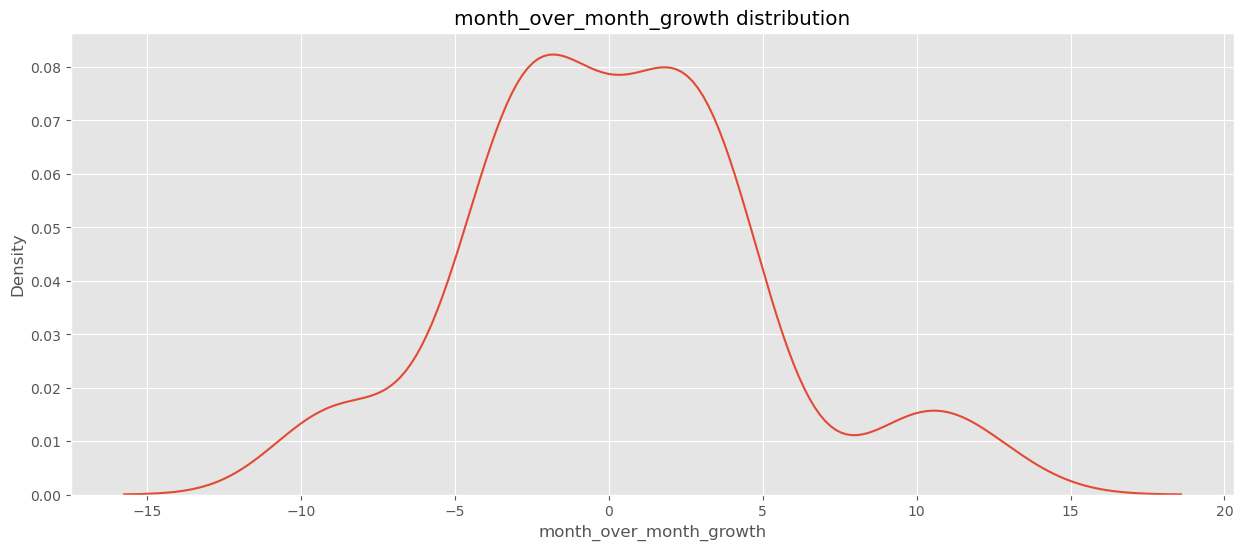

In [ ]:
# plotting the  kde for the numerical columns
for col in numerical_cols:
    plt.figure(figsize=(15,6), dpi=100, facecolor='w', edgecolor='k')
    sns.kdeplot(financial_forecasting_data[col])
    plt.title(f'{col} distribution')
    plt.show()

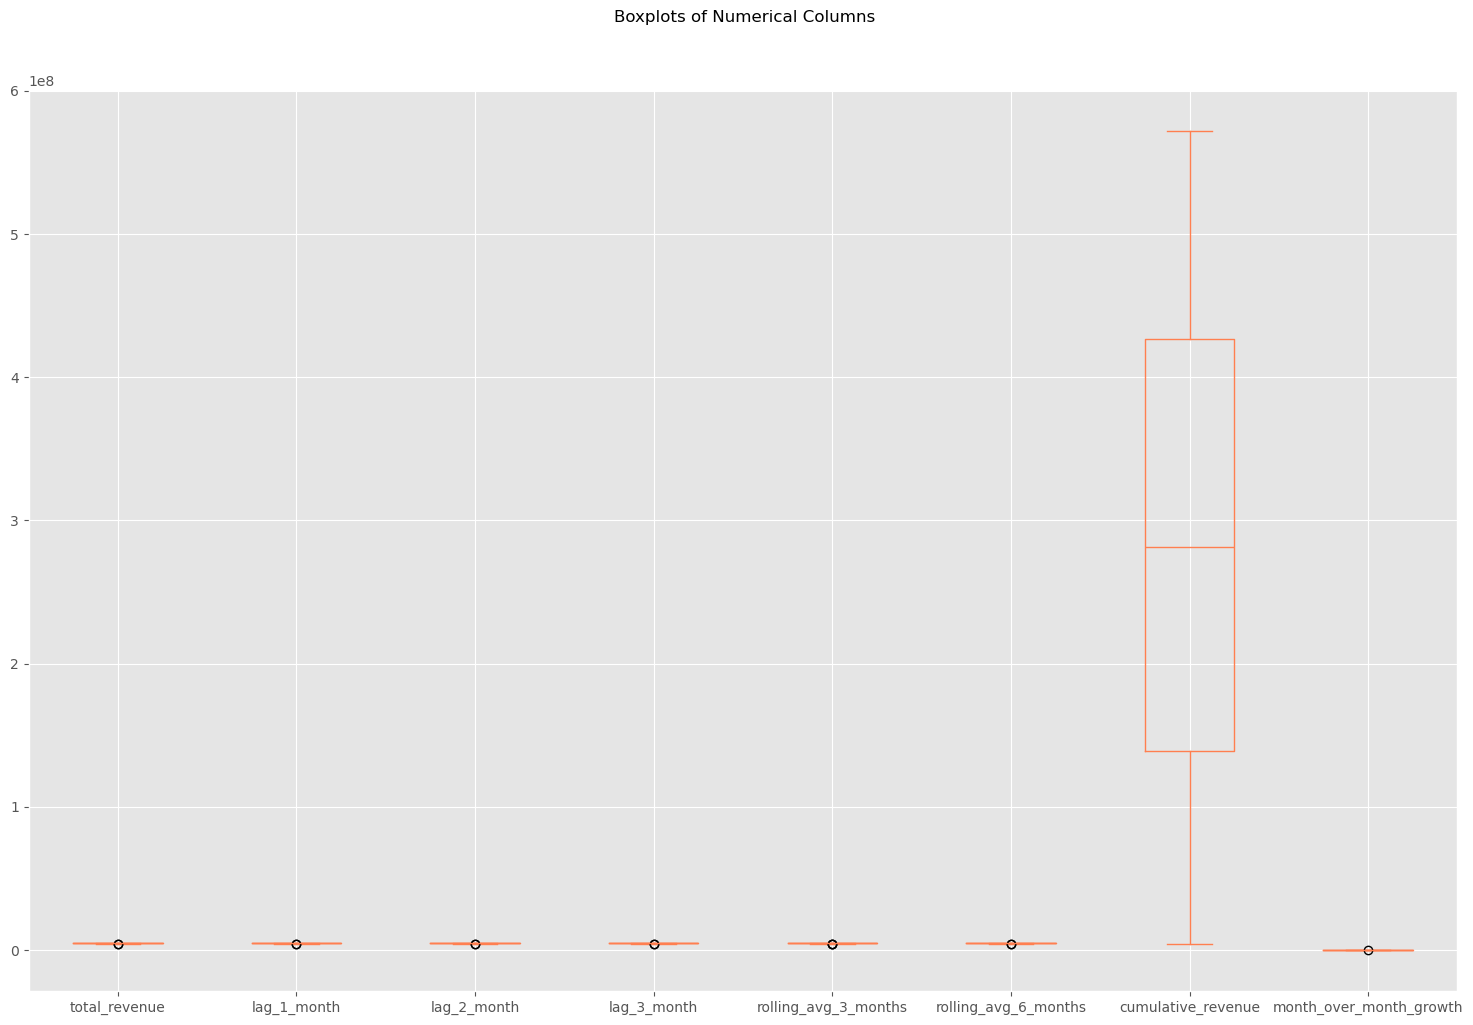

In [ ]:
financial_forecasting_data[numerical_cols].boxplot(figsize=(15,10), color='coral')
plt.suptitle('Boxplots of Numerical Columns', x=0.5, y=1.02, ha='center', fontsize='large')
plt.tight_layout()
plt.show()

In [ ]:
corr_matrix = financial_forecasting_data[numerical_cols].corr().round(2)
corr_matrix

,total_revenue,lag_1_month,lag_2_month,lag_3_month,rolling_avg_3_months,rolling_avg_6_months,cumulative_revenue,month_over_month_growth
total_revenue,1.00,0.42,0.60,0.56,0.84,0.80,0.66,0.51
lag_1_month,0.42,1.00,0.42,0.60,0.76,0.76,0.66,-0.56
lag_2_month,0.60,0.42,1.00,0.42,0.84,0.79,0.67,0.13
lag_3_month,0.56,0.60,0.42,1.00,0.66,0.79,0.67,-0.03
rolling_avg_3_months,0.84,0.76,0.84,0.66,1.00,0.96,0.82,0.04
rolling_avg_6_months,0.80,0.76,0.79,0.79,0.96,1.00,0.86,0.01
cumulative_revenue,0.66,0.66,0.67,0.67,0.82,0.86,1.00,-0.02
month_over_month_growth,0.51,-0.56,0.13,-0.03,0.04,0.01,-0.02,1.00


In [ ]:
corr_matrix['total_revenue'].sort_values(ascending=False)

total_revenue              1.00
rolling_avg_3_months       0.84
rolling_avg_6_months       0.80
cumulative_revenue         0.66
lag_2_month                0.60
lag_3_month                0.56
month_over_month_growth    0.51
lag_1_month                0.42
Name: total_revenue, dtype: float64

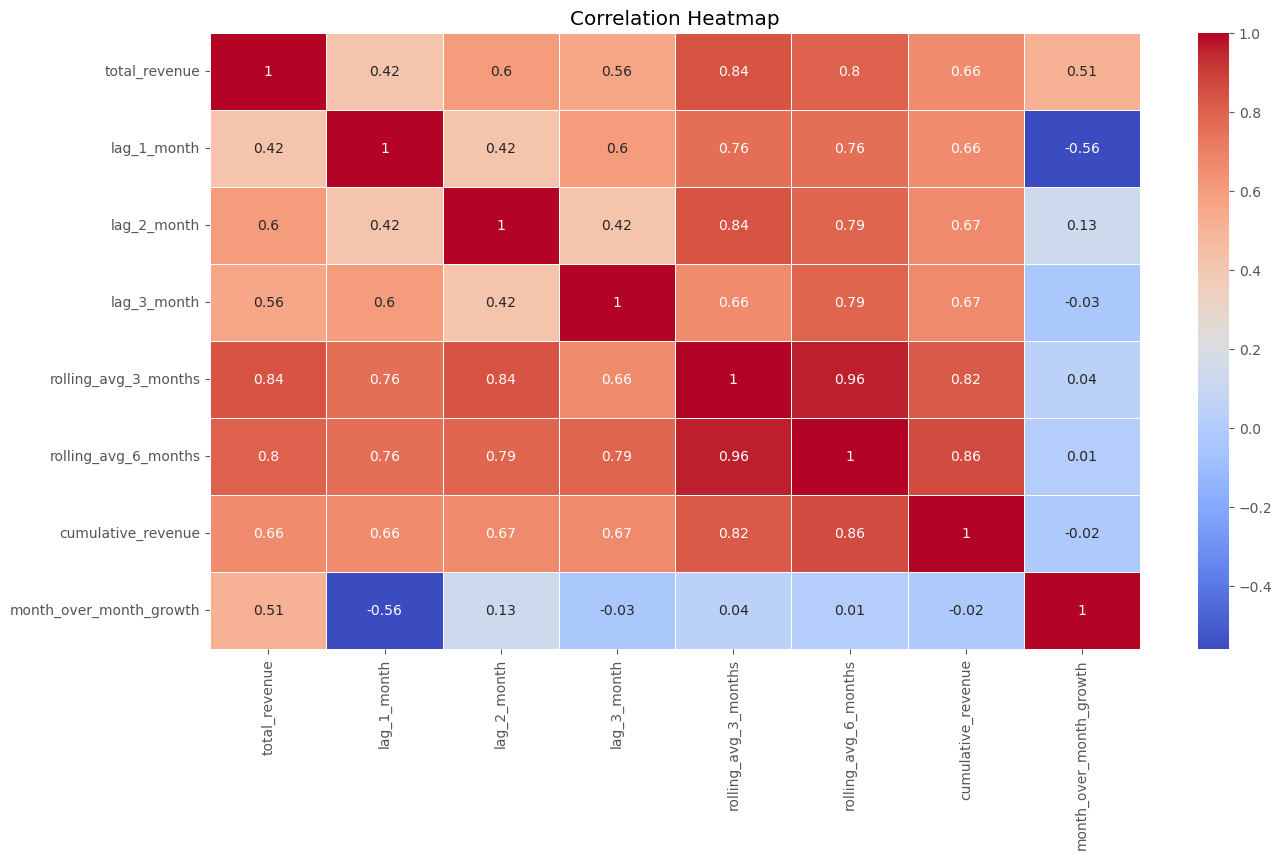

In [ ]:
plt.figure(figsize=(15,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

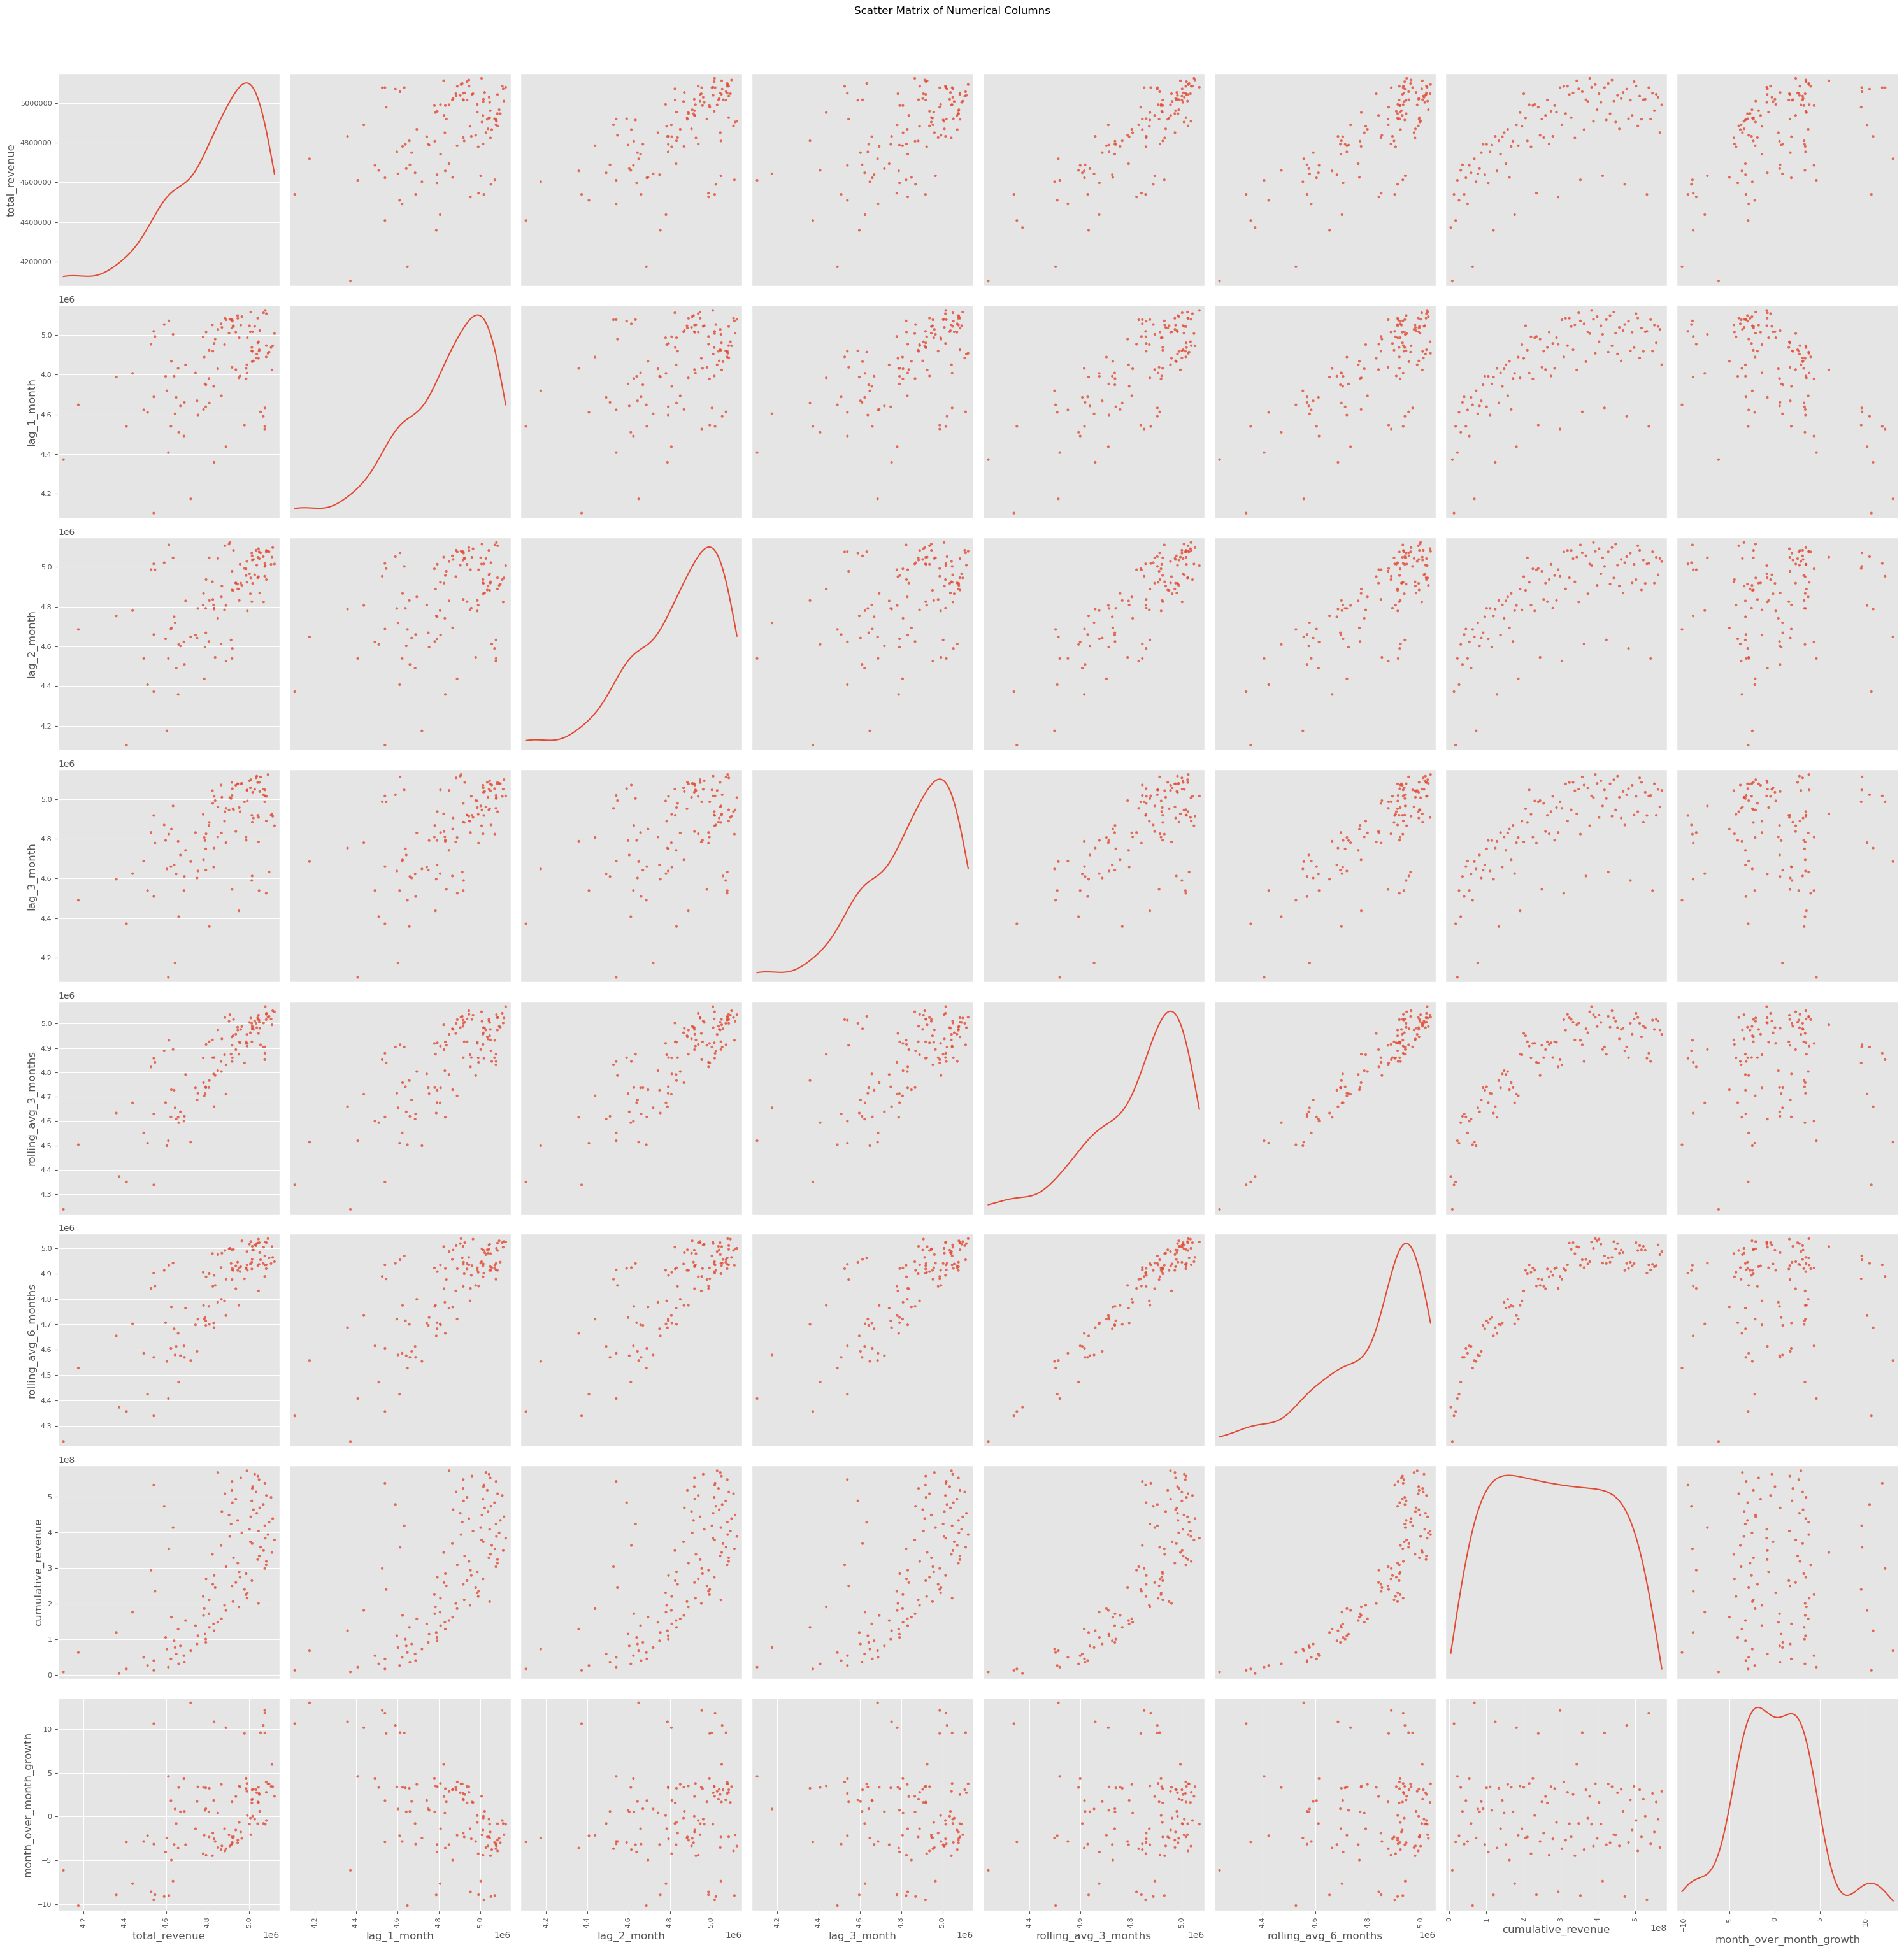

In [ ]:
from pandas.plotting import scatter_matrix

scatter_matrix(financial_forecasting_data[numerical_cols], figsize=(30, 30), alpha=0.8, diagonal='kde')
plt.suptitle('Scatter Matrix of Numerical Columns', x=0.5, y=1.02, ha='center', fontsize='large')
plt.tight_layout()
plt.show()

----

### Spending Patterns
___

In [ ]:
data2 = pd.read_csv("spending_variance_analysis_data.csv")
data2.head()

,transaction_id,user_id,actual_spending,budgeted_spending,variance,variance_pct,total_variance_by_customer,total_variance_by_merchant,monthly_variance
0,22756662,1727,3261.63,37.813430,3223.816570,8525.586257,3.420197e-11,6.357650e+05,-2.962089e-09
1,22453398,1081,6613.44,87.959641,6525.480359,7418.721025,-4.185097e-12,6.357650e+05,1.366401e-08
2,19431468,1147,4613.24,63.828844,4549.411156,7127.516112,-4.670753e-11,6.357650e+05,1.587452e-08
3,10711855,909,1857.46,26.045836,1831.414164,7031.504734,1.328715e-10,6.357650e+05,6.214691e-09
4,17569196,1507,455.00,6.401017,448.598983,7008.245512,-7.080558e-12,2.806425e+06,-1.064326e-08


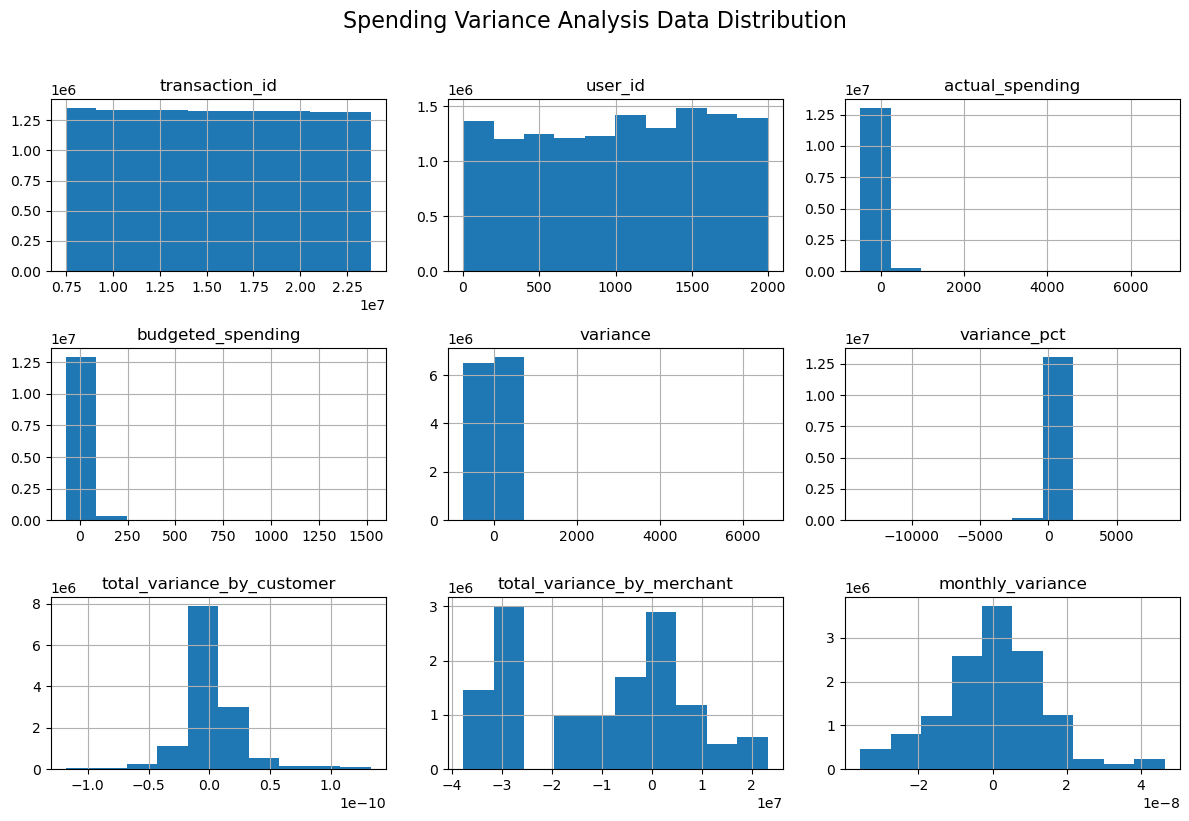

In [ ]:
data2.hist(figsize=(12, 8))
plt.suptitle("Spending Variance Analysis Data Distribution", y=1.02, size=16)
plt.tight_layout()
plt.show()

### Variance Analysis
___

In [ ]:
data3 = pd.read_csv("customer_spending_segmentation_data.csv")
data3.head()


,user_id,mcc_code,transaction_count,total_spending,avg_transaction_value,transaction_frequency
0,1556,5499,844,14317.7,16.9641,6
1,1556,5499,844,14317.7,16.9641,3
2,1556,5499,844,14317.7,16.9641,6
3,1556,5499,844,14317.7,16.9641,6
4,1556,5499,844,14317.7,16.9641,3


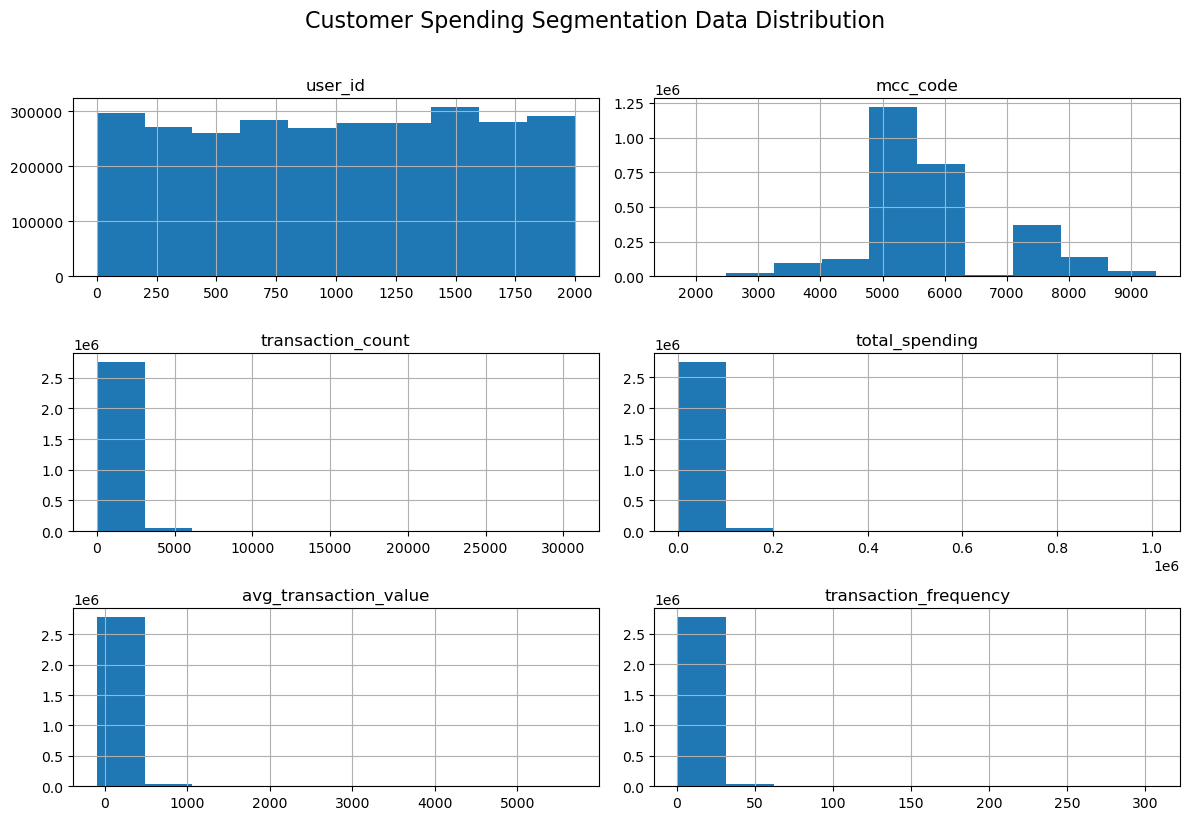

In [ ]:
data3.hist(figsize=(12, 8))
plt.suptitle("Customer Spending Segmentation Data Distribution", y=1.02, size=16)
plt.tight_layout()
plt.show()

### Customer Segmentation
___

In [ ]:
data4 = pd.read_csv("business_intelligence_data.csv")
data4.head()

,transaction_id,transaction_date,user_id,amount,merchant_category,is_fraud
0,7475327,2010-01-01,1556,-77.00,Miscellaneous Food Stores,0.0
1,7475328,2010-01-01,561,14.57,Department Stores,0.0
2,7475329,2010-01-01,1129,80.00,Money Transfer,0.0
3,7475331,2010-01-01,430,200.00,Money Transfer,NaN
4,7475332,2010-01-01,848,46.41,Drinking Places (Alcoholic Beverages),0.0


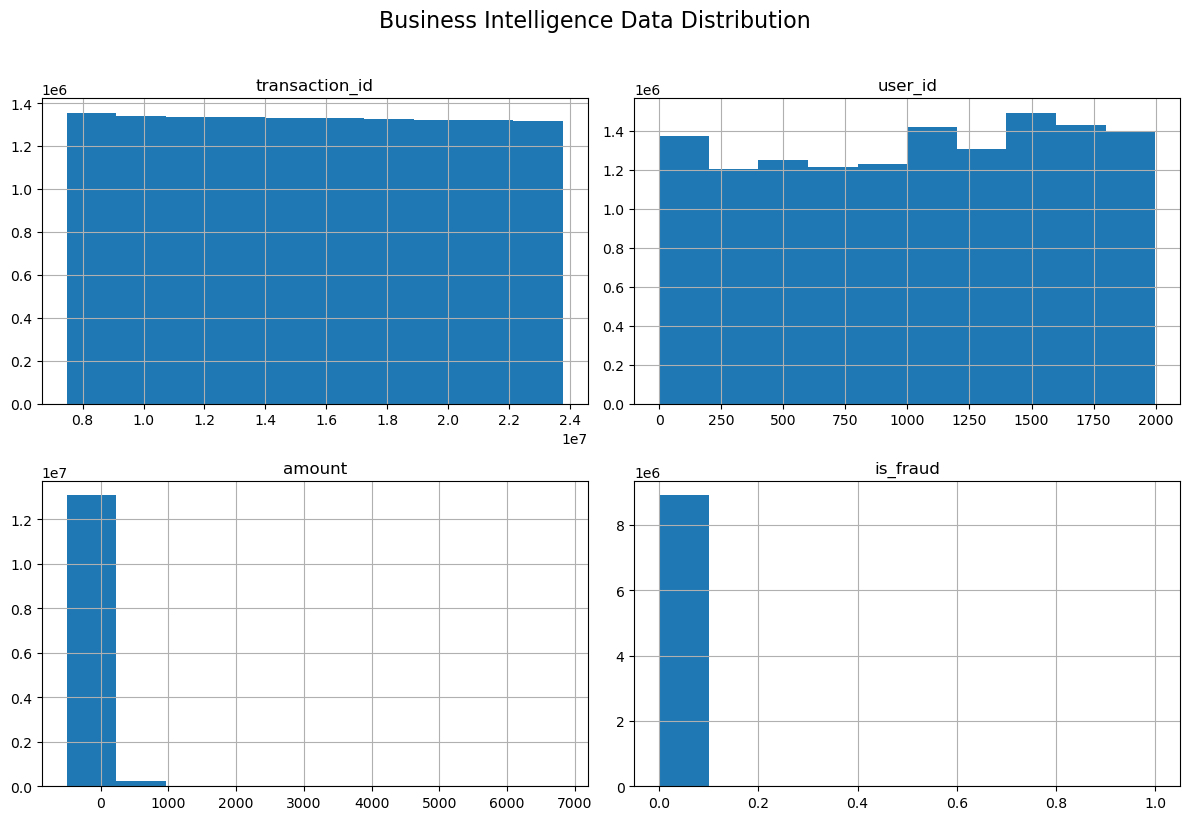

In [ ]:
data4.hist(figsize=(12, 8))
plt.suptitle("Business Intelligence Data Distribution", y=1.02, size=16)
plt.tight_layout()
plt.show()

# 📚 5. Machine Learning Model
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
This section focuses on building machine learning models for financial forecasting and fraud detection. The goal is to predict future revenue and expenses using historical transaction data and identify fraudulent transactions based on transaction features. The models will be evaluated using metrics such as RMSE, MAPE, R² scores, and AUC-ROC curves to assess their predictive performance.
</div>

Export data to Python and train time-series models (ARIMA, XGBoost, LSTM).   
Evaluate model performance using RMSE, MAPE, and R².   
Integrate forecast results into Power BI for visualization.   

In [ ]:
financial_forecasting_data.head()

,month_start,transaction_year,transaction_month,transaction_quarter,total_revenue,lag_1_month,lag_2_month,lag_3_month,rolling_avg_3_months,rolling_avg_6_months,cumulative_revenue,month_over_month_growth
0,2010-01-01,2010,1,1,4372532.12,NaN,NaN,NaN,4.372532e+06,4.372532e+06,4372532.12,NaN
1,2010-02-01,2010,2,1,4103170.24,4372532.12,NaN,NaN,4.237851e+06,4.237851e+06,8475702.36,-6.160318
2,2010-03-01,2010,3,1,4539853.38,4103170.24,4372532.12,NaN,4.338519e+06,4.338519e+06,13015555.74,10.642579
3,2010-04-01,2010,4,2,4407951.33,4539853.38,4103170.24,4372532.12,4.350325e+06,4.355877e+06,17423507.07,-2.905425
4,2010-05-01,2010,5,2,4610601.80,4407951.33,4539853.38,4103170.24,4.519469e+06,4.406822e+06,22034108.87,4.597384


In [ ]:
financial_forecasting_data.describe().round(2)

,month_start,transaction_year,transaction_month,transaction_quarter,total_revenue,lag_1_month,lag_2_month,lag_3_month,rolling_avg_3_months,rolling_avg_6_months,cumulative_revenue,month_over_month_growth
count,115,115.00,115.00,115.00,115.00,115.00,115.00,115.00,115.00,115.00,1.150000e+02,115.00
mean,2014-12-31 08:58:26.086956544,2014.54,6.53,2.51,4859304.06,4855387.10,4848892.32,4843191.89,4854527.82,4846064.56,2.907270e+08,0.19
min,2010-04-01 00:00:00,2010.00,1.00,1.00,4174994.47,4174994.47,4103170.24,4103170.24,4350324.98,4355876.77,1.742351e+07,-10.18
25%,2012-08-16 12:00:00,2012.00,4.00,2.00,4745624.60,4730215.17,4706181.05,4690898.11,4737118.93,4723618.79,1.502240e+08,-2.88
50%,2015-01-01 00:00:00,2015.00,7.00,3.00,4907683.34,4904087.07,4904087.07,4889663.36,4904184.48,4912754.01,2.887001e+08,0.04
75%,2017-05-16 12:00:00,2017.00,9.00,3.00,5015939.76,5015939.76,5015939.76,5014994.19,4983868.05,4962853.65,4.303025e+08,3.17
max,2019-10-01 00:00:00,2019.00,12.00,4.00,5123666.67,5123666.67,5123666.67,5123666.67,5069963.29,5037587.38,5.718355e+08,13.02
std,NaN,2.79,3.40,1.10,194528.14,196393.35,208544.89,212525.42,158332.20,161165.93,1.630004e+08,4.71


In [ ]:
financial_forecasting_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118 entries, 0 to 117
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   month_start              118 non-null    object 
 1   transaction_year         118 non-null    int64  
 2   transaction_month        118 non-null    int64  
 3   transaction_quarter      118 non-null    int64  
 4   total_revenue            118 non-null    float64
 5   lag_1_month              117 non-null    float64
 6   lag_2_month              116 non-null    float64
 7   lag_3_month              115 non-null    float64
 8   rolling_avg_3_months     118 non-null    float64
 9   rolling_avg_6_months     118 non-null    float64
 10  cumulative_revenue       118 non-null    float64
 11  month_over_month_growth  117 non-null    float64
dtypes: float64(8), int64(3), object(1)
memory usage: 11.2+ KB


In [ ]:
def clean_financial_forecasting_function(data):
    """
    Cleans the financial forecasting data:
    1. Converts 'month_start' to datetime format.
    2. Fills missing values using forward fill method.
    3. Drops any remaining NaN values.
    4. Returns the cleaned DataFrame.
    """
    # Import should be at the top of the file, not inside the function
    # import numpy as np
    
    # Convert 'month_start' to datetime format
    data['month_start'] = pd.to_datetime(data['month_start'])
    
    # Fill missing values using forward fill method (fixed deprecated method)
    data.ffill(inplace=True)
    
    # Drop any remaining NaN values created by lagging operations
    data.dropna(inplace=True)
    
    # Print information about the cleaned data
    print(data.info())  # Check data types and null values
    
    return data

# Clean the financial forecasting data
cleaned_data = clean_financial_forecasting_function(financial_forecasting_data)

<class 'pandas.core.frame.DataFrame'>
Index: 115 entries, 3 to 117
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   month_start              115 non-null    datetime64[ns]
 1   transaction_year         115 non-null    int64         
 2   transaction_month        115 non-null    int64         
 3   transaction_quarter      115 non-null    int64         
 4   total_revenue            115 non-null    float64       
 5   lag_1_month              115 non-null    float64       
 6   lag_2_month              115 non-null    float64       
 7   lag_3_month              115 non-null    float64       
 8   rolling_avg_3_months     115 non-null    float64       
 9   rolling_avg_6_months     115 non-null    float64       
 10  cumulative_revenue       115 non-null    float64       
 11  month_over_month_growth  115 non-null    float64       
dtypes: datetime64[ns](1), float64(8), int64(3

In [ ]:
financial_forecasting_data.isnull().sum()

month_start                0
transaction_year           0
transaction_month          0
transaction_quarter        0
total_revenue              0
lag_1_month                0
lag_2_month                0
lag_3_month                0
rolling_avg_3_months       0
rolling_avg_6_months       0
cumulative_revenue         0
month_over_month_growth    0
dtype: int64

In [ ]:
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_percentage_error

# Create Features and Target
X = financial_forecasting_data[['lag_1_month', 'lag_2_month', 'lag_3_month', 'rolling_avg_3_months', 'rolling_avg_6_months']]
y = financial_forecasting_data['total_revenue']

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Train Model
model = XGBRegressor(objective='reg:squarederror', n_estimators=100)
model.fit(X_train, y_train)

# Predict and Evaluate
y_pred = model.predict(X_test)
mape = mean_absolute_percentage_error(y_test, y_pred)
print(f"XGBoost MAPE: {mape:.4f}")


XGBoost MAPE: 0.0079


# 📚 5.2 Time-Series Prerequisites
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
Before building forecasting models we validate the statistical properties of the revenue time series: stationarity (ADF test) and structural decomposition (trend, seasonality, residual). These steps are required prerequisites for ARIMA and inform feature design for any model.
</div>

### Additional Imports for Advanced Analysis

In [ ]:
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from scipy import stats
try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("shap not installed — run: pip install shap")

print("Libraries loaded.")

## 5.2.1 Stationarity Test — Augmented Dickey-Fuller (ADF)
___

A stationary series has constant mean and variance over time.
The ADF test formalises this: **p < 0.05 → stationary** (safe for ARIMA).
If non-stationary, we check whether first-differencing resolves it.

In [ ]:
df_ts = pd.read_csv("financial_forecasting_data.csv")
df_ts['month_start'] = pd.to_datetime(df_ts['month_start'])
df_ts = df_ts.sort_values('month_start').set_index('month_start')

adf = adfuller(df_ts['total_revenue'].dropna())

print("=" * 52)
print("  ADF Test — total_revenue")
print("=" * 52)
print(f"  ADF Statistic : {adf[0]:.4f}")
print(f"  p-value       : {adf[1]:.4f}")
print(f"  Lags Used     : {adf[2]}")
for k, v in adf[4].items():
    print(f"  Critical ({k:3s}) : {v:.4f}")
print()

if adf[1] < 0.05:
    print("✅ STATIONARY — series is ready for ARIMA modelling (p < 0.05)")
    NEEDS_DIFF = False
else:
    print("⚠️  NON-STATIONARY — differencing required (p ≥ 0.05)")
    adf2 = adfuller(df_ts['total_revenue'].diff().dropna())
    print(f"   First-difference p-value: {adf2[1]:.4f}")
    NEEDS_DIFF = True
    if adf2[1] < 0.05:
        print("   ✅ First-differenced series IS stationary → use ARIMA d=1")

## 5.2.2 Time-Series Decomposition
___

Decomposing revenue into **trend**, **seasonality**, and **residual** components reveals
the underlying structure and informs whether seasonal adjustments are warranted.

In [ ]:
ts = df_ts['total_revenue'].dropna()

if len(ts) >= 24:
    decomp = seasonal_decompose(ts, model='additive', period=12)

    fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
    fig.suptitle('Time-Series Decomposition — Monthly Revenue',
                 fontsize=15, fontweight='bold', y=1.01)

    for ax, (data, label, color) in zip(axes, [
        (ts,                'Observed',   'steelblue'),
        (decomp.trend,      'Trend',      'darkorange'),
        (decomp.seasonal,   'Seasonality','seagreen'),
        (decomp.resid,      'Residual',   'crimson'),
    ]):
        ax.plot(data, color=color, linewidth=1.8)
        ax.set_ylabel(label, fontsize=11)
        ax.grid(True, alpha=0.3)

    plt.xlabel('Month', fontsize=11)
    plt.tight_layout()
    plt.show()

    var_r = decomp.resid.dropna().var()
    var_d = (ts - decomp.trend).dropna().var()
    strength = max(0, 1 - var_r / var_d)
    print(f"Seasonality Strength: {strength:.3f}  (0 = none, 1 = strong)")
else:
    ts.plot(figsize=(14, 4), title='Monthly Revenue', color='steelblue')
    plt.ylabel('Revenue ($)'); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()
    print(f"Only {len(ts)} months — need ≥ 24 for full decomposition.")

## 📚 5.3 Model Comparison: ARIMA vs XGBoost (Walk-Forward Validation)
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
Walk-forward (rolling-origin) validation preserves temporal order: the model trains
on all data up to time <em>t</em>, predicts <em>t+1</em>, then expands its window.
This mirrors real-world deployment and produces far more reliable performance
estimates than a single train/test split.
</div>

In [ ]:
from xgboost import XGBRegressor

FEATURES = ['lag_1_month', 'lag_2_month', 'lag_3_month',
            'rolling_avg_3_months', 'rolling_avg_6_months']
TARGET   = 'total_revenue'

df_model = df_ts[FEATURES + [TARGET]].dropna().copy()
n        = len(df_model)
n_test   = max(int(n * 0.2), 6)
n_train  = n - n_test

print(f"Months total: {n}  |  Train: {n_train}  |  Test (walk-forward): {n_test}")

xgb_preds, arima_preds, naive_preds, actuals, pred_dates = [], [], [], [], []

for i in range(n_train, n):
    y_true = df_model[TARGET].iloc[i]

    # XGBoost
    xgb = XGBRegressor(objective='reg:squarederror', n_estimators=150,
                       max_depth=3, learning_rate=0.1, subsample=0.8,
                       random_state=42, verbosity=0)
    xgb.fit(df_model[FEATURES].iloc[:i], df_model[TARGET].iloc[:i])
    xgb_preds.append(float(xgb.predict(df_model[FEATURES].iloc[[i]])[0]))

    # ARIMA(1,1,1)
    try:
        fit = ARIMA(df_model[TARGET].iloc[:i], order=(1, 1, 1)).fit()
        arima_preds.append(float(fit.forecast(steps=1).iloc[0]))
    except Exception:
        arima_preds.append(float(df_model[TARGET].iloc[i - 1]))

    # Naïve baseline (last observed value)
    naive_preds.append(float(df_model[TARGET].iloc[i - 1]))

    actuals.append(y_true)
    pred_dates.append(df_model.index[i])

actuals      = np.array(actuals)
xgb_preds    = np.array(xgb_preds)
arima_preds  = np.array(arima_preds)
naive_preds  = np.array(naive_preds)
print("Walk-forward validation complete.")

### 5.3.1 Performance Comparison Table

In [ ]:
def metrics(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, 1e-9, y_true))) * 100
    r2   = r2_score(y_true, y_pred)
    return {'Model': name,
            'RMSE ($)': round(rmse, 2),
            'MAE ($)':  round(mae,  2),
            'MAPE (%)': round(mape, 2),
            'R²':       round(r2,   4)}

perf_table = pd.DataFrame([
    metrics(actuals, xgb_preds,   'XGBoost (Walk-Forward)'),
    metrics(actuals, arima_preds, 'ARIMA (1,1,1)'),
    metrics(actuals, naive_preds, 'Naïve Baseline'),
])

print("=" * 68)
print("        FORECASTING MODEL COMPARISON — WALK-FORWARD CV")
print("=" * 68)
print(perf_table.to_string(index=False))
print("=" * 68)
best_model = perf_table.loc[perf_table['MAPE (%)'].idxmin(), 'Model']
best_mape  = perf_table['MAPE (%)'].min()
best_r2    = perf_table.loc[perf_table['MAPE (%)'].idxmin(), 'R²']
print(f"\n✅  Best model by MAPE: {best_model}  (MAPE={best_mape:.1f}%, R²={best_r2:.3f})")

### 5.3.2 Forecast vs Actual Plot with 95% Confidence Band

In [ ]:
residuals  = actuals - xgb_preds
std_resid  = residuals.std()

fig, ax = plt.subplots(figsize=(15, 6))

# Training history
ax.plot(df_model.index[:n_train], df_model[TARGET].iloc[:n_train],
        color='steelblue', linewidth=2, label='Historical (Train)')

# Test actuals
ax.plot(pred_dates, actuals, color='steelblue', linewidth=2,
        linestyle='--', label='Actual (Test)')

# XGBoost
ax.plot(pred_dates, xgb_preds, color='darkorange', linewidth=2.5,
        marker='o', markersize=5, label='XGBoost Forecast')

# ARIMA
ax.plot(pred_dates, arima_preds, color='seagreen', linewidth=2,
        linestyle=':', marker='s', markersize=4, label='ARIMA(1,1,1) Forecast')

# 95% confidence band (XGBoost ± 1.96σ of residuals)
ax.fill_between(pred_dates,
                xgb_preds - 1.96 * std_resid,
                xgb_preds + 1.96 * std_resid,
                color='darkorange', alpha=0.15, label='95% Confidence Band')

ax.axvline(df_model.index[n_train], color='gray', linestyle='--',
           linewidth=1.2, label='Train / Test Split')

ax.set_title('Revenue Forecast: XGBoost vs ARIMA — Walk-Forward Validation',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Total Revenue ($)')
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 📚 5.4 Model Interpretability — SHAP Values
___

SHAP (SHapley Additive exPlanations) quantifies each feature's contribution to
every prediction, answering the core analyst question: *what is actually driving
the forecast?* This bridges the gap between a black-box model and actionable
business insight.

In [ ]:
# Retrain XGBoost on the full dataset for SHAP analysis
xgb_final = XGBRegressor(objective='reg:squarederror', n_estimators=150,
                          max_depth=3, learning_rate=0.1, subsample=0.8,
                          random_state=42, verbosity=0)
X_full = df_model[FEATURES]
y_full = df_model[TARGET]
xgb_final.fit(X_full, y_full)

# ── Feature Importance (XGBoost built-in) ─────────────────────────────────
fi = pd.Series(xgb_final.feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(fi.index, fi.values, color='steelblue', edgecolor='white')
ax.bar_label(bars, fmt='%.3f', padding=4, fontsize=10)
ax.set_xlabel('Feature Importance (F-Score)')
ax.set_title('XGBoost Feature Importance', fontsize=13, fontweight='bold')
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# ── SHAP (if available) ────────────────────────────────────────────────────
if SHAP_AVAILABLE:
    explainer   = shap.TreeExplainer(xgb_final)
    shap_values = explainer.shap_values(X_full)

    mean_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values()

    fig, ax = plt.subplots(figsize=(9, 4))
    bars = ax.barh(mean_shap.index, mean_shap.values, color='darkorange', edgecolor='white')
    ax.bar_label(bars, fmt='${:,.0f}', padding=4, fontsize=10)
    ax.set_xlabel('Mean |SHAP Value| — Avg Revenue Impact per Prediction ($)')
    ax.set_title('SHAP Feature Importance', fontsize=13, fontweight='bold')
    ax.grid(True, axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

    shap.summary_plot(shap_values, X_full, plot_type='dot', show=True, plot_size=(10, 4))

    top_feat = mean_shap.idxmax()
    print(f"\n📌 '{top_feat}' has the highest average impact: ${mean_shap.max():,.0f} per prediction.")
else:
    print("Install shap (`pip install shap`) to view SHAP explanations.")

# 📚 6. Enhanced Variance Analysis
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
Variance analysis goes beyond calculating differences. Here we classify variances as
favorable/unfavorable, test their statistical significance, identify root causes by
customer, and communicate findings through a waterfall chart — the format finance
stakeholders expect.
</div>

## 6.1 Favorable vs Unfavorable Variance Classification
___

**Favorable** = actual spending < budget (cost saving). **Unfavorable** = actual > budget (overspend). Statistical significance testing determines which variances warrant action.

In [ ]:
df_var = pd.read_csv("spending_variance_analysis_data.csv")
print("Variance dataset:", df_var.shape)
print("Columns:", df_var.columns.tolist())
df_var.head()

In [ ]:
df_var['variance_type'] = np.where(df_var['variance'] < 0, 'Favorable', 'Unfavorable')
df_var['variance_abs']  = df_var['variance'].abs()

summary_var = df_var.groupby('variance_type').agg(
    count        = ('variance', 'count'),
    total_var    = ('variance', 'sum'),
    avg_var      = ('variance', 'mean'),
    median_var   = ('variance', 'median'),
).round(2)

print("=" * 55)
print("  Variance Classification Summary")
print("=" * 55)
print(summary_var.to_string())
print("=" * 55)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_var[df_var['variance_type']=='Favorable']['variance'],
             bins=50, color='seagreen', alpha=0.7, label='Favorable (Under Budget)')
axes[0].hist(df_var[df_var['variance_type']=='Unfavorable']['variance'],
             bins=50, color='crimson',  alpha=0.7, label='Unfavorable (Over Budget)')
axes[0].axvline(0, color='black', linewidth=1.5, linestyle='--')
axes[0].set_title('Variance Distribution by Type', fontweight='bold')
axes[0].set_xlabel('Variance ($)')
axes[0].set_ylabel('Transaction Count')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].pie(summary_var['count'], labels=summary_var.index,
            colors=['seagreen', 'crimson'], autopct='%1.1f%%',
            startangle=90, textprops={'fontsize': 12})
axes[1].set_title('Transaction Share by Variance Type', fontweight='bold')

plt.tight_layout()
plt.show()

## 6.2 Statistical Significance Test
___

A one-sample t-test determines whether the mean variance is significantly different from zero — i.e., whether the budget model is systematically biased.

In [ ]:
from scipy.stats import ttest_1samp

t_stat, p_val = ttest_1samp(df_var['variance'].dropna(), popmean=0)

print("=" * 55)
print("  One-Sample T-Test: Mean Variance vs Zero")
print("=" * 55)
print(f"  t-statistic  : {t_stat:.4f}")
print(f"  p-value      : {p_val:.6f}")
print(f"  Mean variance: ${df_var['variance'].mean():,.2f}")
print()

if p_val < 0.05:
    direction = 'over-budget (unfavorable)' if df_var['variance'].mean() > 0 else 'under-budget (favorable)'
    print(f"✅ SIGNIFICANT (p < 0.05) — spending is systematically {direction}.")
else:
    print("⚠️  NOT SIGNIFICANT (p ≥ 0.05) — deviations appear to be random noise.")

VAR_P_VALUE = p_val  # used in executive summary

## 6.3 Root Cause Analysis — Top Variance Customers
___

Identifying which customers drive the largest budget deviations focuses remediation efforts.

In [ ]:
top_cust_var = (df_var.groupby('user_id')['variance']
                .sum()
                .reindex(df_var.groupby('user_id')['variance'].sum().abs()
                         .nlargest(15).index))

bar_colors = ['crimson' if v > 0 else 'seagreen' for v in top_cust_var.values]

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(top_cust_var.index.astype(str), top_cust_var.values,
       color=bar_colors, edgecolor='white')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Top 15 Customers by Total Variance\n(Red = Over Budget | Green = Under Budget)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('User ID')
ax.set_ylabel('Total Variance ($)')
ax.tick_params(axis='x', rotation=45)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("Top 10 customers by variance impact:")
print(df_var.groupby('user_id').agg(
    total_variance = ('variance', 'sum'),
    avg_variance   = ('variance', 'mean'),
    tx_count       = ('variance', 'count'),
    unfav_count    = ('variance_type', lambda x: (x=='Unfavorable').sum())
).sort_values('total_variance', key=abs, ascending=False).head(10).round(2).to_string())

## 6.4 Waterfall Chart — Variance by Customer
___

The waterfall chart shows how individual customer variances accumulate to the net total — the standard deliverable for variance reporting to finance leadership.

In [ ]:
cust_totals = (df_var.groupby('user_id')['variance']
               .sum()
               .sort_values(key=abs, ascending=False))

# Top 10 customers + Others bucket
TOP_N   = 10
top_mv  = cust_totals.head(TOP_N)
other_v = cust_totals.iloc[TOP_N:].sum()

wf_labels = list(top_mv.index.astype(str)) + ['Others', 'NET TOTAL']
wf_values = list(top_mv.values) + [other_v, cust_totals.sum()]

# Running totals for bar bottoms
bottoms = []
running = 0
for v in wf_values[:-1]:      # exclude NET TOTAL from accumulation
    bottoms.append(running)
    running += v
bottoms.append(0)              # NET TOTAL starts from 0

bar_cols = (['crimson' if v > 0 else 'seagreen' for v in wf_values[:-1]]
            + ['steelblue'])

fig, ax = plt.subplots(figsize=(14, 6))
for i, (label, val, bot, col) in enumerate(zip(wf_labels, wf_values, bottoms, bar_cols)):
    ax.bar(i, val, bottom=bot, color=col, edgecolor='white', width=0.6)
    ax.text(i, bot + val + abs(cust_totals.sum()) * 0.01,
            f'${val:+,.0f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(range(len(wf_labels)))
ax.set_xticklabels(wf_labels, rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Cumulative Variance ($)')
ax.set_title('Variance Waterfall — Spending vs Budget by Customer\n'
             '(Red = Over Budget | Green = Under Budget | Blue = Net Total)',
             fontsize=13, fontweight='bold')
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# 📚 7. RFM Analysis & Customer Segmentation
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
RFM (Recency, Frequency, Monetary) analysis is the industry-standard framework for
customer financial profiling. We score each customer on all three dimensions, apply
K-Means clustering to surface natural segments, and label each group with a
business-meaningful description.
</div>

## 7.1 Build RFM Table
___

In [ ]:
df_bi   = pd.read_csv("business_intelligence_data.csv")
df_cust = pd.read_csv("customer_spending_segmentation_data.csv")

df_bi['transaction_date'] = pd.to_datetime(df_bi['transaction_date'])
ref_date = df_bi['transaction_date'].max() + pd.Timedelta(days=1)

# Recency: days since last transaction
recency = (df_bi.groupby('user_id')['transaction_date']
           .max()
           .apply(lambda d: (ref_date - d).days)
           .reset_index()
           .rename(columns={'transaction_date': 'recency_days'}))

# Frequency + Monetary from segmentation data
freq_mon = (df_cust.groupby('user_id')
            .agg(frequency=('transaction_count', 'sum'),
                 monetary  =('total_spending',   'sum'))
            .reset_index())

rfm = recency.merge(freq_mon, on='user_id', how='inner').dropna()
print(f"RFM table: {rfm.shape[0]:,} customers")
print(rfm[['recency_days','frequency','monetary']].describe().round(2))

## 7.2 RFM Scoring (Quintiles, 1–5)
___

Each dimension scored 1–5. For recency: *lower days = higher score* (more recent = better). For frequency and monetary: higher = better.

In [ ]:
rfm['R'] = pd.qcut(rfm['recency_days'], q=5, labels=[5,4,3,2,1]).astype(int)
rfm['F'] = pd.qcut(rfm['frequency'].rank(method='first'), q=5, labels=[1,2,3,4,5]).astype(int)
rfm['M'] = pd.qcut(rfm['monetary'].rank(method='first'),  q=5, labels=[1,2,3,4,5]).astype(int)
rfm['RFM_score'] = rfm['R'] + rfm['F'] + rfm['M']

print("RFM Score distribution:")
print(rfm[['R','F','M','RFM_score']].describe().round(2))

## 7.3 K-Means Clustering — Elbow Method
___

In [ ]:
scaler     = MinMaxScaler()
rfm_scaled = scaler.fit_transform(rfm[['recency_days', 'frequency', 'monetary']])

inertias = []
K_RANGE  = range(2, 11)
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    km.fit(rfm_scaled)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(K_RANGE, inertias, 'o-', color='steelblue', linewidth=2, markersize=7)
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Inertia (Within-Cluster SS)')
ax.set_title('K-Means Elbow Method — Optimal Customer Segments',
             fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7.4 Segment Profiles & Visualisation
___

In [ ]:
OPTIMAL_K = 4
km_final  = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init='auto')
rfm['cluster'] = km_final.fit_predict(rfm_scaled)

profile = (rfm.groupby('cluster')
           .agg(n_customers =('user_id',    'count'),
                avg_recency  =('recency_days','mean'),
                avg_frequency=('frequency',  'mean'),
                avg_monetary =('monetary',   'mean'),
                avg_rfm      =('RFM_score',  'mean'))
           .round(2)
           .sort_values('avg_rfm', ascending=False))

seg_names = {
    profile.index[0]: 'Champions',
    profile.index[1]: 'Loyal Customers',
    profile.index[2]: 'At-Risk',
    profile.index[3]: 'Lost / Inactive',
}
rfm['segment']    = rfm['cluster'].map(seg_names)
profile['segment']= [seg_names[i] for i in profile.index]

print("=" * 70)
print("  Customer Segment Profiles")
print("=" * 70)
print(profile[['segment','n_customers','avg_recency',
                'avg_frequency','avg_monetary','avg_rfm']].to_string(index=False))
print("=" * 70)

In [ ]:
SEG_COLORS = {
    'Champions':      '#2ecc71',
    'Loyal Customers':'#3498db',
    'At-Risk':        '#e67e22',
    'Lost / Inactive':'#e74c3c',
}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Scatter: Frequency vs Monetary
for seg, grp in rfm.groupby('segment'):
    axes[0].scatter(grp['frequency'], grp['monetary'], s=15, alpha=0.5,
                    color=SEG_COLORS[seg], label=seg)
axes[0].set_xlabel('Frequency (# Transactions)')
axes[0].set_ylabel('Monetary (Total Spend $)')
axes[0].set_title('Segments — Frequency vs Monetary', fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# Bubble: Recency vs Frequency, size = Monetary
for seg, grp in rfm.groupby('segment'):
    s = grp.sample(min(500, len(grp)), random_state=42)
    axes[1].scatter(s['recency_days'], s['frequency'],
                    s=s['monetary'] / s['monetary'].max() * 200,
                    alpha=0.4, color=SEG_COLORS[seg], label=seg)
axes[1].set_xlabel('Recency (Days Since Last Purchase)')
axes[1].set_ylabel('Frequency (# Transactions)')
axes[1].set_title('RFM Bubble Chart\n(Bubble Size = Monetary Value)',
                  fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.suptitle('RFM Customer Segmentation', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print("Customer count by segment:")
print(rfm['segment'].value_counts().to_string())

# 📚 8. Financial KPIs
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
Domain-specific financial KPIs demonstrate applied business acumen beyond model-building.
We calculate Customer Lifetime Value (CLV), flag churn risk, and run a Pareto 80/20
concentration analysis to surface where the business's revenue is concentrated.
</div>

## 8.1 Customer Lifetime Value (CLV)
___

`CLV = avg_transaction_value × monthly_frequency × lifespan_months`  

Lifespan is estimated from each customer's first-to-last transaction window.

In [ ]:
cust_kpi = df_bi.groupby('user_id').agg(
    first_tx     = ('transaction_date', 'min'),
    last_tx      = ('transaction_date', 'max'),
    tx_count     = ('transaction_id',   'count'),
    total_spend  = ('amount',           'sum'),
    avg_tx_val   = ('amount',           'mean'),
).reset_index()

cust_kpi['lifespan_days']   = (cust_kpi['last_tx'] - cust_kpi['first_tx']).dt.days + 1
cust_kpi['lifespan_months'] = (cust_kpi['lifespan_days'] / 30).clip(lower=1)
cust_kpi['monthly_freq']    = cust_kpi['tx_count'] / cust_kpi['lifespan_months']
cust_kpi['CLV']             = cust_kpi['avg_tx_val'] * cust_kpi['monthly_freq'] * cust_kpi['lifespan_months']

print("CLV Distribution:")
print(cust_kpi['CLV'].describe().round(2))

fig, ax = plt.subplots(figsize=(12, 4))
cap = cust_kpi['CLV'].quantile(0.95)
ax.hist(cust_kpi['CLV'].clip(upper=cap), bins=60,
        color='steelblue', edgecolor='white')
ax.axvline(cust_kpi['CLV'].median(), color='darkorange', linewidth=2,
           label=f"Median CLV: ${cust_kpi['CLV'].median():,.0f}")
ax.axvline(cust_kpi['CLV'].mean(),   color='crimson', linewidth=2, linestyle='--',
           label=f"Mean CLV: ${cust_kpi['CLV'].mean():,.0f}")
ax.set_title('Customer Lifetime Value Distribution (clipped at 95th pct)',
             fontweight='bold')
ax.set_xlabel('CLV ($)')
ax.set_ylabel('Customers')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8.2 Churn Risk Identification
___

Customers inactive for **90–180 days** are **At-Risk**. Those inactive **180+ days** are classified as **Churned**.

In [ ]:
cust_kpi['days_inactive'] = (ref_date - cust_kpi['last_tx']).dt.days

def churn_label(d):
    if d > 180: return 'Churned'
    if d > 90:  return 'At-Risk'
    return 'Active'

cust_kpi['churn_status'] = cust_kpi['days_inactive'].apply(churn_label)

churn_summary = cust_kpi.groupby('churn_status').agg(
    customers  = ('user_id',  'count'),
    avg_clv    = ('CLV',      'mean'),
    total_clv  = ('CLV',      'sum'),
).round(2)

print("=" * 55)
print("  Churn Risk Summary")
print("=" * 55)
print(churn_summary.to_string())
print("=" * 55)

CHURN_COLORS = {'Active': '#2ecc71', 'At-Risk': '#e67e22', 'Churned': '#e74c3c'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

counts = cust_kpi['churn_status'].value_counts()
axes[0].pie(counts, labels=counts.index,
            colors=[CHURN_COLORS[l] for l in counts.index],
            autopct='%1.1f%%', startangle=90, textprops={'fontsize': 12})
axes[0].set_title('Customers by Churn Status', fontweight='bold')

total_clv = churn_summary['total_clv']
axes[1].bar(total_clv.index, total_clv.values,
            color=[CHURN_COLORS[l] for l in total_clv.index], edgecolor='white')
axes[1].set_title('Total CLV at Stake by Churn Status', fontweight='bold')
axes[1].set_ylabel('Total CLV ($)')
axes[1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

at_risk_clv = churn_summary.get('total_clv', {}).get('At-Risk', 0)
try:
    at_risk_clv = churn_summary.loc['At-Risk', 'total_clv']
except Exception:
    at_risk_clv = 0
print(f"\n💡 ${at_risk_clv:,.0f} in CLV is at risk from customers approaching churn.")

## 8.3 Revenue Concentration — Pareto (80/20) Analysis
___

The Pareto principle tests whether a small fraction of customers drives the majority of revenue — a critical concentration risk indicator.

In [ ]:
pareto = (cust_kpi[['user_id', 'total_spend']]
          .sort_values('total_spend', ascending=False)
          .copy())
pareto['cum_pct']  = pareto['total_spend'].cumsum() / pareto['total_spend'].sum() * 100
pareto['cust_pct'] = np.arange(1, len(pareto) + 1) / len(pareto) * 100

threshold_80 = pareto[pareto['cum_pct'] >= 80].iloc[0]['cust_pct']
print(f"📊 Pareto Finding: {threshold_80:.1f}% of customers generate 80% of revenue")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(pareto['cust_pct'], pareto['cum_pct'],
        color='steelblue', linewidth=2.5, label='Cumulative Revenue %')
ax.axhline(80, color='darkorange', linestyle='--', linewidth=1.5,
           label='80% Revenue Line')
ax.axvline(threshold_80, color='crimson', linestyle='--', linewidth=1.5,
           label=f'{threshold_80:.1f}% of Customers')
ax.fill_between(pareto['cust_pct'], pareto['cum_pct'], alpha=0.08, color='steelblue')
ax.set_xlabel('Cumulative % of Customers (ranked by spend)')
ax.set_ylabel('Cumulative % of Revenue')
ax.set_title('Pareto Chart — Revenue Concentration (80/20 Analysis)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 📚 9. Executive Summary
___

<div style="font-family: Avenir, sans-serif; font-size: 16px; line-height: 1.6; color: white; background-color: #333; padding: 10px; border-radius: 5px;">
This section synthesises all analytical findings into actionable business insights —
the format a financial analyst would present to senior stakeholders.
</div>

In [ ]:
# ── Pull key stats computed throughout the notebook ───────────────────────
var_pct_unf   = (df_var['variance_type'] == 'Unfavorable').mean() * 100
mean_var      = df_var['variance'].mean()
sig_str       = "statistically significant" if VAR_P_VALUE < 0.05 else "not statistically significant"
at_risk_pct   = (cust_kpi['churn_status'] == 'At-Risk').mean()   * 100
churned_pct   = (cust_kpi['churn_status'] == 'Churned').mean()   * 100
champ_pct     = (rfm['segment'] == 'Champions').mean()            * 100

print("=" * 70)
print("   EXECUTIVE SUMMARY — FINANCIAL DATA ANALYTICS FINDINGS")
print("=" * 70)
print()
print("1. REVENUE FORECASTING")
print(f"   Best model : {best_model}")
print(f"   MAPE       : {best_mape:.1f}%  |  R2 : {best_r2:.3f}")
print("   Time-series decomposition confirms seasonal patterns.")
print("   Confidence bands quantify planning uncertainty.")
print()
print("2. VARIANCE ANALYSIS")
print(f"   {var_pct_unf:.1f}% of transactions are unfavorable (over budget).")
print(f"   Mean variance ${mean_var:+,.2f} per transaction is {sig_str}.")
print("   Waterfall chart identifies top customers driving total variance.")
print()
print("3. CUSTOMER SEGMENTATION (RFM)")
print(f"   {OPTIMAL_K} segments discovered via K-Means on RFM scores.")
print(f"   Champions ({champ_pct:.1f}% of base): highest recency, frequency & spend.")
print("   At-Risk / Inactive: targeted re-engagement campaigns recommended.")
print()
print("4. FINANCIAL RISK")
print(f"   {at_risk_pct:.1f}% of customers are at churn risk (90-180 days inactive).")
print(f"   {churned_pct:.1f}% are presumed churned (180+ days inactive).")
print(f"   Pareto: {threshold_80:.1f}% of customers drive 80% of revenue.")
print("   High concentration risk; diversification of customer base advised.")
print()
print("5. RECOMMENDED ACTIONS")
print("   1. Use XGBoost forecast + confidence band for quarterly targets.")
print("   2. Investigate top-variance customers; tighten budget assumptions.")
print("   3. Launch win-back campaign for At-Risk segment.")
print(f"   4. Monitor top {threshold_80:.0f}% of customers as concentration risk.")
print("=" * 70)